# Monte Carlo (MC) Methods

## MC Integrations with Uniform Probability Densities

Given a function $f(x)$ on $[a, b]$, we draw $N$ uniform random samples $X_1, \dots, X_N \sim \text{Uniform}(a, b)$ with probability density $p_X(x) = \frac{1}{b-a}$.

1. **Sample Mean Estimator:**
   $$\langle f \rangle = \frac{1}{N} \sum_{j=1}^N f(X_j), \quad \langle f^2 \rangle = \frac{1}{N} \sum_{j=1}^N f(X_j)^2$$
   By the Law of Large Numbers, as $N \to \infty$, the integral is approximated by:
   $$I = \int_a^b f(s)ds \approx (b - a)\langle f \rangle$$

2. **Error Estimation via Central Limit Theorem (CLT):**
   For large $N$, the sample mean $\langle f \rangle$ follows a normal distribution centered at $E(f(X))$ with variance $\frac{V(f(X))}{N}$.
   * **Sample Variance of $f$:** $V(f(X)) \approx \langle f^2 \rangle - \langle f \rangle^2$
   * **Standard Error of $\langle f \rangle$:** $\sigma_{\langle f \rangle} = \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$
   * **Standard Error of the Integral $I$:** $\sigma_I = (b - a)\sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$

Key takeaway: The Monte Carlo integration error decreases at a rate of $\mathcal{O}(1/\sqrt{N})$, regardless of the number of dimensions!

In [13]:
# a visual verification of the 1/√N convergence rate:

import numpy as np
import matplotlib.pyplot as plt

def monte_carlo_integrate(f, a, b, N, seed=42):
    """
    Approximates the integral of f(x) from a to b using N uniform samples.
    Returns the integral estimate and the CLT standard error.
    """
    rng = np.random.default_rng(seed) # Use a random number generator for reproducibility
    
    # 1. Draw N uniform samples in [a, b]
    X = rng.uniform(a, b, N) # Draw N uniform samples in [a, b]
    
    # 2. Evaluate Y_j = f(X_j)
    Y = f(X)
    
    # 3. Compute <f> and <f^2>
    f_mean = np.mean(Y)
    f_sq_mean = np.mean(Y**2)
    
    # 4. Estimate variance V(Y) = <f^2> - <f>^2
    var_f = f_sq_mean - f_mean**2
    
    # 5. Compute integral estimate and standard error scaled by (b - a)
    integral_est = (b - a) * f_mean
    error_est = (b - a) * np.sqrt(var_f / N) # CLT standard error = sqrt(V(Y)/N)
    
    return integral_est, error_est

# Example: Integrate f(x) = sin(x) from 0 to pi (Exact answer = 2.0)
f = np.sin
a, b = 0, np.pi
exact_val = 2.0

N = 10_000
est, err = monte_carlo_integrate(f, a, b, N)
actual_err = abs(est - exact_val)

print(f"Monte Carlo Estimate (N={N}): {est:.6f}")
print(f"Exact Integral Value         : {exact_val:.6f}")
print(f"CLT Estimated Error (1 sigma): ±{err:.6f}")
print(f"Actual Absolute Error        : {actual_err:.6f}")

Monte Carlo Estimate (N=10000): 2.003473
Exact Integral Value         : 2.000000
CLT Estimated Error (1 sigma): ±0.009663
Actual Absolute Error        : 0.003473


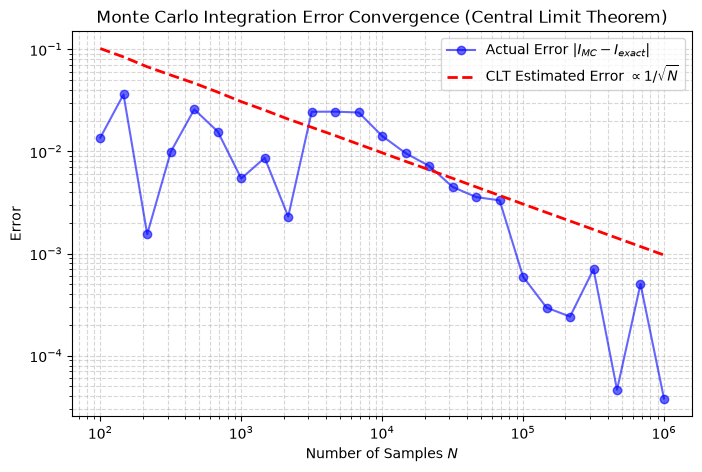

In [17]:
# --- Plot Error Convergence vs N ---
N_values = np.logspace(2, 6, 25, dtype=int) # arr = np.logspace(0, 3, num=4) - Output: [   1.   10.  100. 1000.]
actual_errors = []
clt_errors = []

for n in N_values:
    integral_n, err_n = monte_carlo_integrate(f, a, b, n, seed=101)
    actual_errors.append(abs(integral_n - exact_val))
    clt_errors.append(err_n)

plt.figure(figsize=(8, 5))
plt.loglog(N_values, actual_errors, 'o-', alpha=0.6, label='Actual Error $|I_{MC} - I_{exact}|$', color='blue')
plt.loglog(N_values, clt_errors, 'r--', linewidth=2, label=r'CLT Estimated Error $\propto 1/\sqrt{N}$')
plt.xlabel('Number of Samples $N$')
plt.ylabel('Error')
plt.title('Monte Carlo Integration Error Convergence (Central Limit Theorem)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

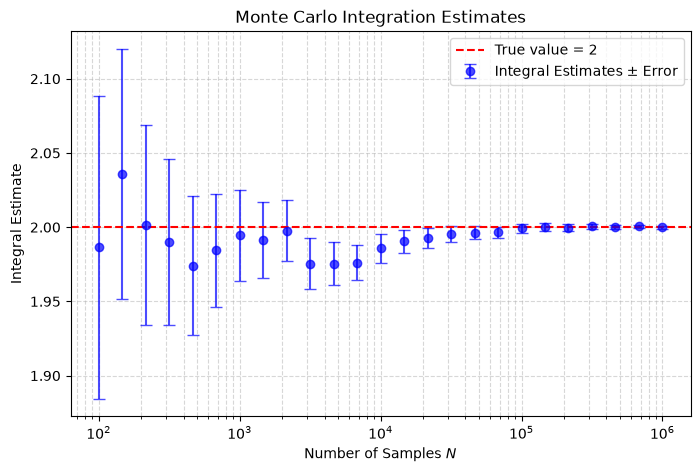

In [16]:
# --- Plot Integral estimates vs N ---
N_values = np.logspace(2, 6, 25, dtype=int)
integral_estimates = []
integral_errors = []

for n in N_values:
    integral_n, err_n = monte_carlo_integrate(f, a, b, n, seed=101)
    integral_estimates.append(integral_n)
    integral_errors.append(err_n)

plt.figure(figsize=(8, 5))
plt.errorbar(
    N_values,
    integral_estimates,
    yerr=integral_errors,
    fmt='o',
    linestyle='none',  # Do not connect the points
    capsize=4,
    alpha=0.7,
    color='blue',
    label='Integral Estimates ± Error',
)
plt.axhline(2, color='red', linestyle='--', linewidth=1.5, label='True value = 2')

plt.xscale('log')
plt.xlabel('Number of Samples $N$')
plt.ylabel('Integral Estimate')
plt.title('Monte Carlo Integration Estimates')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.show()

## MC Integration with Non-Uniform Probability Densities
When an integral over a $D$-dimensional volume $\mathcal{V}$ is weighted by a normalized non uniform probability density $p(\vec{x})$ (such that $\int_{\mathcal{V}} p(\vec{x}) d^D x = 1$), we draw $N$ independent random vectors $\vec{x}_1, \dots, \vec{x}_N \sim p(\vec{x})$:

$$\int_{\mathcal{V}} p(\vec{x}) f(\vec{x}) d^D x \approx \langle f \rangle \pm \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

where:
$$\langle f \rangle \equiv \frac{1}{N} \sum_{i=1}^N f(\vec{x}_i), \qquad \langle f^2 \rangle \equiv \frac{1}{N} \sum_{i=1}^N f(\vec{x}_i)^2$$

* **Justification:** The **Law of Large Numbers** guarantees convergence to the exact integral as $N \to \infty$, and the **Central Limit Theorem** guarantees that the estimate is Gaussian-distributed with standard error $\propto 1/\sqrt{N}$ (independent of dimension $D$).
* **Note on Uniform Volume $\mathcal{V}$:** If we want to integrate $\int_{\mathcal{V}}  p(\vec{x}) f(\vec{x}) d^D x$ using uniform sampling over a volume $V = \int_{\mathcal{V}} d^D x$, then $p(\vec{x}) = 1/V$, which means we get:

$$\int_{\mathcal{V}} f(\vec{x}) d^D x \approx V \langle f \rangle \pm V \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

### Pseudorandom Number Generators (PRNGs)
* Computers are deterministic and generate **pseudorandom** sequences using modulus operations, bit shifting, and shuffling.
* **Mersenne Twister (`MT19937`):** A fast, high-quality PRNG with a period of $2^{19937}-1$ that passes the Diehard test suite.

The code below demonstrates:

1. Using the Mersenne Twister (MT19937) explicitly in NumPy.   
2. 1D Non-Uniform Monte Carlo Integration (sampling from an exponential distribution $p_X(x)= e^{-x}, x \in [0,∞))$.   
3. D-Dimensional Monte Carlo Integration (integrating a 5D function over a 5D Gaussian distribution $p(x)$).

In [ ]:
# Initialize NumPy's random generator explicitly with the Mersenne Twister (MT19937)
bit_gen = np.random.MT19937(seed=42)
rng = np.random.Generator(bit_gen)
print(f"Using PRNG: {rng.bit_generator.__class__.__name__}\n")

Using PRNG: MT19937



In [9]:
# =====================================================================
# Example 1: Non-Uniform 1D Monte Carlo Integration
# Goal: Evaluate I = \int_0^\infty e^{-x} * cos(x) dx
# Here, p_X(x) = e^{-x} (Exponential distribution with scale=1)
#       f(x)   = cos(x)
# Exact analytical answer: 0.5
# =====================================================================
N = 100_000

# 1. Sample X_1, ..., X_N directly from p_X(x) = e^{-x}
X_exp = rng.exponential(scale=1.0, size=N) # scale = 1/lambda, where lambda is the rate parameter: e^(-lambda*x). Here, lambda = 1, so scale = 1/lambda = 1.

# 2. Apply f(x) = cos(x)
Y = np.cos(X_exp)

# 3. Compute <f>, <f^2>, and CLT uncertainty
f_mean = np.mean(Y)
f_sq_mean = np.mean(Y**2)
uncertainty = np.sqrt((f_sq_mean - f_mean**2) / N)

print("--- 1D Non-Uniform Monte Carlo (Exponential p_X) ---")
print(f"Integral: \\int_0^\\infty e^(-x) cos(x) dx")
print(f"MC Estimate : {f_mean:.6f} ± {uncertainty:.6f}")
print(f"Exact Value : 0.500000")
print(f"Actual Error: {abs(f_mean - 0.5):.6f}\n")

--- 1D Non-Uniform Monte Carlo (Exponential p_X) ---
Integral: \int_0^\infty e^(-x) cos(x) dx
MC Estimate : 0.499041 ± 0.001875
Exact Value : 0.500000
Actual Error: 0.000959



In [12]:
# =====================================================================
# Example 2: D-Dimensional Monte Carlo Integration (D = 5)
# Goal: Evaluate I = \int_{R^D} p(\vec{x}) * ||\vec{x}||^2 d^D x
# where p(\vec{x}) is the D-dimensional Standard Normal distribution:
#       p(\vec{x}) = (2*pi)^(-D/2) * exp(-||\vec{x}||^2 / 2)
# and f(\vec{x}) = x_1^2 + x_2^2 + ... + x_D^2
# Exact analytical answer: E[sum(X_i^2)] = D * 1 = 5.0
# =====================================================================
D = 5
N_dim = 100_000

# 1. Draw N independent D-dimensional vectors \vec{x}_i from standard normal p(\vec{x})
# Shape of X_vec is (N_dim, D) 
X_vec = rng.normal(loc=0.0, scale=1.0, size=(N_dim, D)) # loc=0.0 (mean), scale=1.0 (std dev) for standard normal distribution
print(f"X_vec:\n{X_vec}")

# 2. Evaluate f(\vec{x}_i) = sum of squares along each D-dimensional vector
f_vals = np.sum(X_vec**2, axis=1)

# 3. Compute <f>, <f^2>, and CLT uncertainty
f_mean_D = np.mean(f_vals)
f_sq_mean_D = np.mean(f_vals**2)
uncertainty_D = np.sqrt((f_sq_mean_D - f_mean_D**2) / N_dim)

print(f"--- {D}D Monte Carlo Integration (Multivariate Gaussian p(x)) ---")
print(f"MC Estimate : {f_mean_D:.6f} ± {uncertainty_D:.6f}")
print(f"Exact Value : {float(D):.6f}")
print(f"Actual Error: {abs(f_mean_D - D):.6f}")

X_vec:
[[-0.09620087  0.60170805  0.81783429 -1.64702718 -0.35696102]
 [-0.31857696 -1.16250237 -1.05716897 -0.48008613 -1.09849012]
 [ 1.77727812 -0.81191691 -0.18118261 -0.12807031  0.87835093]
 ...
 [-0.7030029  -1.34571191 -0.7908694  -0.49342146 -0.92946308]
 [-0.20528156 -0.53203329 -0.26114983 -0.50151195  0.29269182]
 [-2.6029967  -2.45727756 -0.80420315  0.0472284   0.54943807]]
--- 5D Monte Carlo Integration (Multivariate Gaussian p(x)) ---
MC Estimate : 4.982538 ± 0.009977
Exact Value : 5.000000
Actual Error: 0.017462


## Importance Sampling Method

Simple Monte Carlo integration ($\int_a^b f(x)dx \approx \frac{b-a}{N}\sum_{j=1}^N f(x_j)$ with uniform $x_j$) performs poorly when $f(x)$ is sharply peaked or oscillates rapidly, because the variance $V(f)$ is very large.

**Importance Sampling** reduces the variance by introducing a normalized probability density $g(x) > 0$ ($\int_a^b g(x)dx = 1$) that mimics the shape of $f(x)$, so that the ratio:
$$h(x) = \frac{f(x)}{g(x)}$$
is as close to a **flat constant** as possible.

We rewrite the integral as an expectation over the probability density $g(x)$:
$$\int_a^b f(x)dx = \int_a^b \frac{f(x)}{g(x)} g(x) dx = \int_a^b h(x) g(x) dx \approx \frac{1}{N} \sum_{j=1}^N h(x_j) \pm \sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}$$
where the sample points $x_1, \dots, x_N$ are drawn from the probability distribution $g(x)$.

**Why it works:**
* Because $g(x)$ is large where $f(x)$ is peaked, more sample points $x_j$ are automatically placed in the important peaked regions.
* Because $h(x) = f(x)/g(x)$ is nearly flat, its variance $\langle h^2 \rangle - \langle h \rangle^2$ is much smaller than the variance of $f(x)$, yielding a drastically smaller error for the same $N$.

Exact Integral Value       : 15.607967

Simple MC Estimate         : 14.753283 ± 1.209133 (Actual err: 0.854683)
Importance Sampling Est.   : 15.626230 ± 0.264329 (Actual err: 0.018264)

Error Reduction Factor     : 4.6x smaller uncertainty!


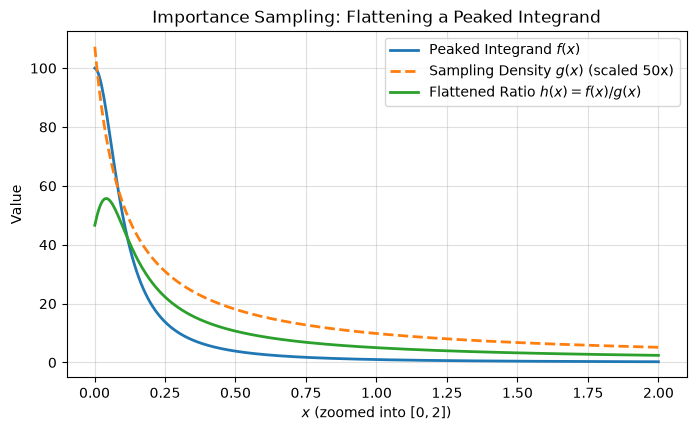

In [ ]:
# =====================================================================
# Example 3: Importance Sampling for a Sharply Peaked Integrand
# Goal: Evaluate I = \int_0^10 f(x) dx, where f(x) = 1 / (x^2 + 0.01)
# Exact analytical answer: I = 10 * arctan(100) ≈ 15.707963267
# =====================================================================

rng = np.random.default_rng(42)
N = 5_000
a, b = 0.0, 10.0

# Sharply peaked function near x = 0: f(x) = 1 / (x^2 + 0.01)

def f(x):
    return 1.0 / (x**2 + 0.01)

exact_val = 10.0 * np.arctan(100.0)

# -------------------------------------------------------------------------
# 1. Simple Monte Carlo (Uniform x_j in [a, b])
# -------------------------------------------------------------------------
x_unif = rng.uniform(a, b, N)
f_vals = (b - a) * f(x_unif)

mc_simple = np.mean(f_vals)
err_simple = np.sqrt((np.mean(f_vals**2) - mc_simple**2) / N)

# -------------------------------------------------------------------------
# 2. Importance Sampling using g(x)
# Choose a normalized probability density g(x) on [0, 10] that also peaks at 0:
# Let g(x) = C / (x + 0.1), where C = 1 / ln(101) so that \int_0^10 g(x) dx = 1
# -------------------------------------------------------------------------
norm_C = 1.0 / np.log(101.0)

def g(x):
    return norm_C / (x + 0.1)

def h(x):
    return f(x) / g(x)

# Sample x_j from g(x) using Inverse Transform Sampling:
# CDF G(x) = C * ln(10*(x + 0.1)) = u  =>  x = 0.1 * (101^u - 1)
u = rng.uniform(0.0, 1.0, N)
x_imp = 0.1 * (101.0**u - 1.0) # x sampled from g(x) using inverse transform sampling

# Evaluate h(x_j) = f(x_j) / g(x_j)
h_vals = h(x_imp)

mc_imp = np.mean(h_vals)
err_imp = np.sqrt((np.mean(h_vals**2) - mc_imp**2) / N)

print(f"Exact Integral Value       : {exact_val:.6f}\n")
print(f"Simple MC Estimate         : {mc_simple:.6f} ± {err_simple:.6f} (Actual err: {abs(mc_simple - exact_val):.6f})")
print(f"Importance Sampling Est.   : {mc_imp:.6f} ± {err_imp:.6f} (Actual err: {abs(mc_imp - exact_val):.6f})")
print(f"\nError Reduction Factor     : {err_simple / err_imp:.1f}x smaller uncertainty!")

# --- Plot f(x), g(x), and flat h(x) ---
x_grid = np.linspace(0.001, 2.0, 500)
plt.figure(figsize=(8, 4.5))
plt.plot(x_grid, f(x_grid), label='Peaked Integrand $f(x)$', lw=2)
plt.plot(x_grid, g(x_grid) * 50, '--', label='Sampling Density $g(x)$ (scaled 50x)', lw=2)
plt.plot(x_grid, h(x_grid), label='Flattened Ratio $h(x) = f(x)/g(x)$', lw=2)
plt.xlabel('$x$ (zoomed into $[0, 2]$)')
plt.ylabel('Value')
plt.title('Importance Sampling: Flattening a Peaked Integrand')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

### Generalized Theorem of MC Integration with Importance Sampling

To integrate any function $f$ over a volume $V$, we can draw $N$ random points $x_0, \dots, x_{N-1}$ from any normalized probability density $p(x)$ satisfying:
$$\int_V p \, dV = 1$$

The **Generalized Fundamental Theorem of Monte Carlo Integration** estimates the integral and its $1\sigma$ statistical error as:
$$I \equiv \int_V f \, dV = \int_V \frac{f}{p} p \, dV \approx \left\langle \frac{f}{p} \right\rangle \pm \sqrt{\frac{\langle f^2/p^2 \rangle - \langle f/p \rangle^2}{N}}$$

where the angle brackets denote arithmetic averages over the $N$ points $x_i \sim p(x)$:
$$\left\langle \frac{f}{p} \right\rangle = \frac{1}{N} \sum_{i=0}^{N-1} \frac{f(x_i)}{p(x_i)}, \qquad \left\langle \frac{f^2}{p^2} \right\rangle = \frac{1}{N} \sum_{i=0}^{N-1} \left(\frac{f(x_i)}{p(x_i)}\right)^2$$

* **Special Case (Uniform Sampling):** When points are chosen uniformly over volume $V$, the constant probability density is $p(x) = \frac{1}{V}$. Substituting $p = 1/V$ into the generalized formula factors out $V$:
  $$I \approx V \langle f \rangle \pm V \sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$
* **Zero-Variance Ideal:** If $p(x)$ is chosen proportional to $|f(x)|$, the ratio $f(x)/p(x)$ becomes constant, making the variance $\langle f^2/p^2 \rangle - \langle f/p \rangle^2$ vanish!

In [ ]:
# =====================================================================
# Generalized Monte Carlo Integration (Importance Sampling)   
# =====================================================================

import numpy as np

def mc_generalized(f, p, sample_from_p, N):

    """
    Implements Equation: Generalized Monte Carlo Integration.
    
    Parameters:
    - f: function f(x) to integrate
    - p: normalized probability density function p(x) such that int p dV = 1
    - sample_from_p: function(N) that returns N random samples drawn from p(x)
    - N: number of sample points
    
    Returns:
    - est: integral estimate <f/p>
    - err: 1-sigma error estimate sqrt((<f^2/p^2> - <f/p>^2) / N)
    """

    # 1. Draw N samples x_0, ..., x_{N-1} from probability density p
    x = sample_from_p(N)
    
    # 2. Compute the weighted ratios w_i = f(x_i) / p(x_i)
    ratios = f(x) / p(x)
    
    # 3. Compute arithmetic means <f/p> and <f^2/p^2>
    mean_fp = np.mean(ratios) 
    mean_f2p2 = np.mean(ratios**2) 
    
    # 4. Compute 1-sigma standard error
    error = np.sqrt((mean_f2p2 - mean_fp**2) / N)
    
    return mean_fp, error


# =====================================================================
# Test Problem: Integrate f(x) = e^{-2x} on [0, 5]
# Exact value: (1 - e^{-10}) / 2 ≈ 0.4999773
# =====================================================================
rng = np.random.default_rng(42)
a, b = 0.0, 5.0
V = b - a  # 1D volume (length of interval)
N = 10_000

f = lambda x: np.exp(-2.0 * x)
exact_val = 0.5 * (1.0 - np.exp(-10.0))

# --- Case 1: Special Case of Uniform Sampling (p(x) = 1 / V) ---
p_uniform = lambda x: np.full_like(x, 1.0 / V)
sample_uniform = lambda n: rng.uniform(a, b, n)

est_unif, err_unif = mc_generalized(f, p_uniform, sample_uniform, N)

# --- Case 2: Non-Uniform Sampling (Truncated Exponential p(x) on [0, 5]) ---
# Let p(x) = C * e^{-x} on [0, 5], where C = 1 / (1 - e^{-5}) so \int_0^5 p(x)dx = 1
norm_C = 1.0 / (1.0 - np.exp(-5.0))
p_exp = lambda x: norm_C * np.exp(-x)
# Inverse transform sampling for p(x) = C * e^{-x} on [0, 5]:
sample_exp = lambda n: -np.log(1.0 - rng.uniform(0.0, 1.0, n) / norm_C)

est_imp, err_imp = mc_generalized(f, p_exp, sample_exp, N)

print(f"Exact Integral Value                  : {exact_val:.6f}\n")
print(f"1. Uniform Special Case (p = 1/V)     : {est_unif:.6f} ± {err_unif:.6f}")
print(f"2. Non-Uniform Sampling (p ~ e^{{-x}})  : {est_imp:.6f} ± {err_imp:.6f}")
print(f"\nVariance reduction factor (err_unif / err_imp): {err_unif / err_imp:.2f}x")

Exact Integral Value                  : 0.499977

1. Uniform Special Case (p = 1/V)     : 0.503304 ± 0.009997
2. Non-Uniform Sampling (p ~ e^{-x})  : 0.497081 ± 0.002850

Variance reduction factor (err_unif / err_imp): 3.51x


### Inverse Transform Importance Sampling

Random number generators produce uniform deviates $U \sim \text{Uniform}(0, 1)$ with probability density $p_U(u) = 1$ for $0 \le u \le 1$. To sample a random variable $Y$ with a desired target probability density $p_Y(y)$, we apply a strictly increasing transformation $Y = \phi(U)$.

Because $\phi$ is strictly increasing, an infinitesimal interval $[u, u + du]$ maps one-to-one onto $[y, y + dy]$ where $y = \phi(u)$. The probability of finding $U$ in $du$ must equal the probability of finding $Y$ in $dy$:
   $$p_Y(y)\,dy = p_U(u)\,du$$
   Solving for $p_Y(y)$ in terms of the inverse function $u = \phi^{-1}(y)$ gives:
   $$p_Y(y) = p_U(u)\frac{du}{dy} = p_U\left(\phi^{-1}(y)\right)\frac{d\phi^{-1}(y)}{dy}$$

Substituting the Uniform Density $p_U(u) = 1$, the differential relation simplifies to:
   $$du = p_Y(y)\,dy$$

Integrate the left-hand side from $u' = 0$ to $u$, and the right-hand side from the corresponding lower limit $y' = \phi(0)$ to $y' = \phi(u)$:
   $$\int_0^u du' = \int_{\phi(0)}^{\phi(u)} p_Y(y')\,dy'$$
   * Evaluating the left integral gives:
     $$\int_0^u du' = \left[ u' \right]_0^u = u - 0 = u$$
   * By definition, the right integral is the Cumulative Distribution Function (CDF) $F_Y(y) = \int_{-\infty}^y p_Y(s)\,ds$ evaluated at $y = \phi(u)$ (since $p_Y(s) = 0$ below the minimum value $\phi(0)$):
     $$\int_{\phi(0)}^{\phi(u)} p_Y(y')\,dy' = F_Y(\phi(u))$$

Equating both sides gives:
   $$u = F_Y(\phi(u)) = F_Y(y)$$
   Because $F_Y$ is strictly increasing, its inverse $F_Y^{-1}$ is unique. Applying $F_Y^{-1}$ to both sides yields the transformation rule:
   $$\phi(u) = F_Y^{-1}(u) \quad \Longrightarrow \quad \boxed{Y = F_Y^{-1}(U)}$$


### An Example

Consider the normalized exponential probability density on the finite interval $0 \le y \le b$:
$$p_Y(y) = \frac{e^{-y}}{1 - e^{-b}}, \qquad 0 \le y \le b$$

*(Check normalization: $\int_0^b \frac{e^{-y}}{1 - e^{-b}}\,dy = \frac{1}{1 - e^{-b}}\left[-e^{-y}\right]_0^b = \frac{-e^{-b} - (-e^0)}{1 - e^{-b}} = \frac{1 - e^{-b}}{1 - e^{-b}} = 1$.)*

**Step A: Compute the Cumulative Distribution Function $F_Y(y)$**
Integrate $p_Y(s)$ from the lower bound $s = 0$ up to $s = y$:
$$F_Y(y) = \int_0^y p_Y(s)\,ds = \int_0^y \frac{e^{-s}}{1 - e^{-b}}\,ds = \frac{-e^{-y} - (-e^0)}{1 - e^{-b}} = \frac{1 - e^{-y}}{1 - e^{-b}}$$

**Step B: Invert $F_Y(y) = u$ to Solve for $y = F_Y^{-1}(u)$**
 
Set the CDF equal to a uniform deviate $u \in [0, 1]$:
   $$u = \frac{1 - e^{-y}}{1 - e^{-b}}$$

   $$e^{-y} = 1 - (1 - e^{-b})u$$
Take the natural logarithm ($\ln$) of both sides:
   $$\ln\left(e^{-y}\right) = \ln\left(1 - (1 - e^{-b})u\right)$$
   $$-y = \ln\left(1 - (1 - e^{-b})u\right)$$
   $$y = F_Y^{-1}(u) = -\ln\left(1 - (1 - e^{-b})u\right)$$

*(Boundary check: When $u = 0$, $y = -\ln(1) = 0$. When $u = 1$, $y = -\ln(1 - (1 - e^{-b})) = -\ln(e^{-b}) = b$. Thus $u \in [0, 1]$ maps onto $y \in [0, b]$.)*

Now to evaluate an integral $I = \int_0^3 \frac{e^{-s}}{1 + s/9}\,ds \approx 0.873109$:

1. Generate $N$ uniform random numbers $u_i \sim \text{Uniform}(0, 1)$.
2. Transform them into exponentially distributed samples $s_i \in [0, 3]$ via:
   $$s_i = F_Y^{-1}(u_i) = -\ln\left(1 - (1 - e^{-3})u_i\right)$$
3. Evaluate the importance-weighted function $h(s) = \frac{f(s)}{p_Y(s)}$, where the $e^{-s}$ terms cancel out analytically:
   $$h(s_i) = \frac{\frac{e^{-s_i}}{1 + s_i/9}}{\frac{e^{-s_i}}{1 - e^{-3}}} = \frac{1 - e^{-3}}{1 + s_i/9}$$
4. Compute the sample mean $\langle h \rangle = \frac{1}{N}\sum_{i=1}^N h(s_i)$ and CLT error $\sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}$.

      N |       Naive MC ± Error |  Importance Sampling ± Error
-----------------------------------------------------------------
     10 |  1.004449 ±  0.315859 |     0.879116 ±  0.022356
    100 |  0.935162 ±  0.070484 |     0.881274 ±  0.005983
   1000 |  0.910474 ±  0.024978 |     0.872084 ±  0.001856
  10000 |  0.871729 ±  0.007661 |     0.873240 ±  0.000590
 100000 |  0.871633 ±  0.002430 |     0.873158 ±  0.000187


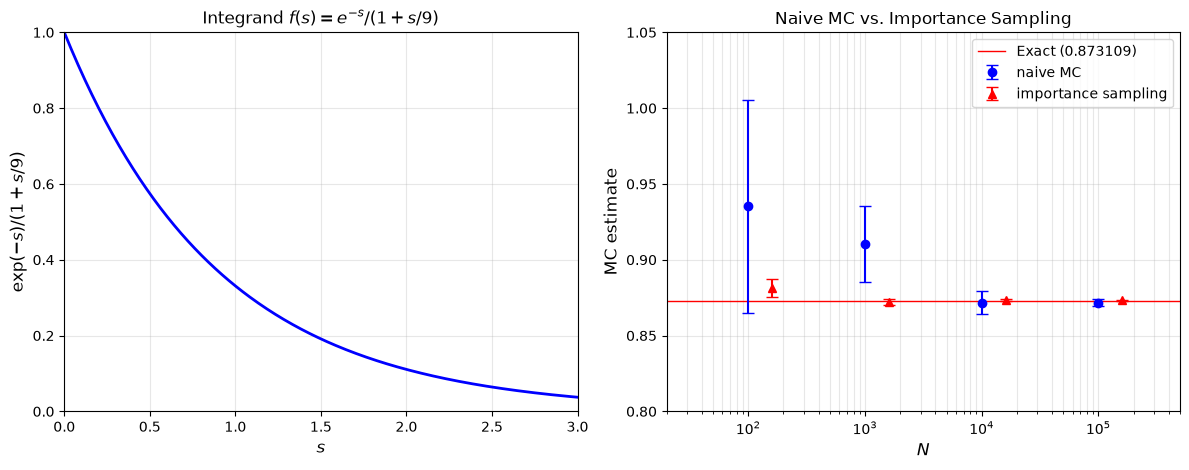

In [34]:
# =====================================================================
# Importance Sampling for a Sharply Peaked Integrand
# =====================================================================

rng = np.random.default_rng(52)
b = 3.0
exact_val = 0.873109

# 1. Define the integrand f(s), sampling density p_Y(s), and inverse CDF F_Y^{-1}(u)
def f(s):
    return np.exp(-s) / (1.0 + s / 9.0)

def p_Y(s, b=3.0):
    return np.exp(-s) / (1.0 - np.exp(-b))

def inv_cdf(u, b=3.0):
    """Inverse Transform: F_Y^{-1}(u) = -ln(1 - (1 - e^{-b})u)"""
    return -np.log(1.0 - (1.0 - np.exp(-b)) * u)

# 2. Run Naive MC and Importance Sampling 
N_list = [10**1, 10**2, 10**3, 10**4, 10**5]
naive_ests, naive_errs = [], []
imp_ests, imp_errs = [], []

print(f"{'N':>7} | {'Naive MC ± Error':>22} | {'Importance Sampling ± Error':>28}")
print("-" * 65)

for N in N_list:
    # --- Naive Uniform MC ---
    s_unif = rng.uniform(0.0, b, N)
    vals_naive = b * f(s_unif)
    est_n = np.mean(vals_naive)
    err_n = np.sqrt((np.mean(vals_naive**2) - est_n**2) / N)
    naive_ests.append(est_n)
    naive_errs.append(err_n)
    
    # --- Importance Sampling via Transformation Method ---
    u = rng.uniform(0.0, 1.0, N)
    s_imp = inv_cdf(u, b=b)
    vals_imp = f(s_imp) / p_Y(s_imp, b=b)
    est_i = np.mean(vals_imp)
    err_i = np.sqrt((np.mean(vals_imp**2) - est_i**2) / N)
    imp_ests.append(est_i)
    imp_errs.append(err_i)
    
    print(f"{N:7d} | {est_n:9.6f} ± {err_n:9.6f} | {est_i:12.6f} ± {err_i:9.6f}")

# 3. Reproduce Fig. 6 from the article
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: Plot of the integrand e^{-s} / (1 + s/9)
s_grid = np.linspace(0, b, 300)
ax1.plot(s_grid, f(s_grid), 'b-', lw=2)
ax1.set_xlim(0, 3)
ax1.set_ylim(0, 1)
ax1.set_xlabel('$s$', fontsize=12)
ax1.set_ylabel(r'$\exp(-s)/(1 + s/9)$', fontsize=12)
ax1.set_title('Integrand $f(s) = e^{-s}/(1 + s/9)$')
ax1.grid(True, alpha=0.3)

# Right Panel: MC Estimates with Error Bars vs N
N_arr = np.array(N_list, dtype=float)
ax2.axhline(exact_val, color='red', lw=1, label='Exact (0.873109)')
ax2.errorbar(N_arr, naive_ests, yerr=naive_errs, fmt='bo', capsize=4, label='naive MC')
# Offset importance sampling x-positions slightly (N * 1.6) just like Fig. 6 so error bars don't overlap
ax2.errorbar(N_arr * 1.6, imp_ests, yerr=imp_errs, fmt='r^', capsize=4, label='importance sampling')

ax2.set_xscale('log')
ax2.set_xlim(20, 5e5)
ax2.set_ylim(0.8, 1.05)
ax2.set_xlabel('$N$', fontsize=12)
ax2.set_ylabel('MC estimate', fontsize=12)
ax2.set_title('Naive MC vs. Importance Sampling')
ax2.legend()
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

## The Rejection Method (von Neumann Acceptance-Rejection Sampling)

When a target probability density $p_X(x)$ on $a \le x \le b$ cannot be easily integrated and inverted analytically, we use the **Rejection Method**.

**Core Principle:** Sampling $x$ from a 1D density $p_X(x)$ is equivalent to sampling a 2D point $(x, y)$ uniformly within the **area under the curve** $y = p_X(x)$ and keeping its $x$-coordinate.

#### 1. Simple Box Rejection (Uniform Envelope)
1. Enclose $p_X(x)$ in a bounding box of width $[a, b]$ and height $M = \max(p_X(x))$.
2. Generate uniform coordinates:
   $$x \sim \text{Uniform}(a, b), \qquad y \sim \text{Uniform}\left(0, \max(p_X(x))\right)$$
3. **Acceptance Criterion:**
   * If $y \le p_X(x)$ (point lies below the curve), **accept** $x$.
   * If $y > p_X(x)$ (point lies above the curve), **reject** $x$ and repeat.
* **Efficiency (Acceptance Probability):** $\text{Efficiency} = \frac{\text{Area under} \, \, p_X(x)}{\text{Area of box}} = \frac{\int_a^b p_X(x)\,dx}{(b - a)\max(p_X(x))}$.

#### 2. General Rejection with a Comparison Function $f(x) \ge p_X(x)$
If $p_X(x)$ is sharply peaked, a rectangular box wastes most samples in the empty region above the tails. Instead, choose a **comparison (envelope) function** $f(x)$ such that:
$$f(x) \ge p_X(x) \quad \forall \, \, x \in [a, b]$$
where $f(x)$ has an invertible cumulative distribution and can be sampled via the **Transformation Method**:
1. Sample candidate $x$ from the normalized density $q(x) = \frac{f(x)}{\int_a^b f(s)\,ds}$ using $x = F_q^{-1}(u_1)$ with $u_1 \sim \text{Uniform}(0, 1)$.
2. Sample a vertical height uniformly under the comparison curve at $x$:
   $$y \sim \text{Uniform}(0, f(x)) \quad \Longleftrightarrow \quad y = u_2 \cdot f(x), \quad u_2 \sim \text{Uniform}(0, 1)$$
3. **Accept** $x$ if $y \le p_X(x)$; otherwise reject and repeat.
* **Efficiency:** $\frac{\int_a^b p_X(x)\,dx}{\int_a^b f(x)\,ds}$, which approaches $100\%$ the closer $f(x)$ hugs $p_X(x)$.

[ True  True  True ...  True  True  True]
--- Part 1: Double-Peak Box Rejection ---
Total trials: 5000 | Accepted: 3647 | Acceptance Rate: 72.9%

--- Part 2: Peaked Function (Box vs. Comparison Function f(x)) ---
Box Rejection Acceptance Rate        : 22.0%
Comparison f(x) Acceptance Rate      : 84.6% (3.8x more efficient!)


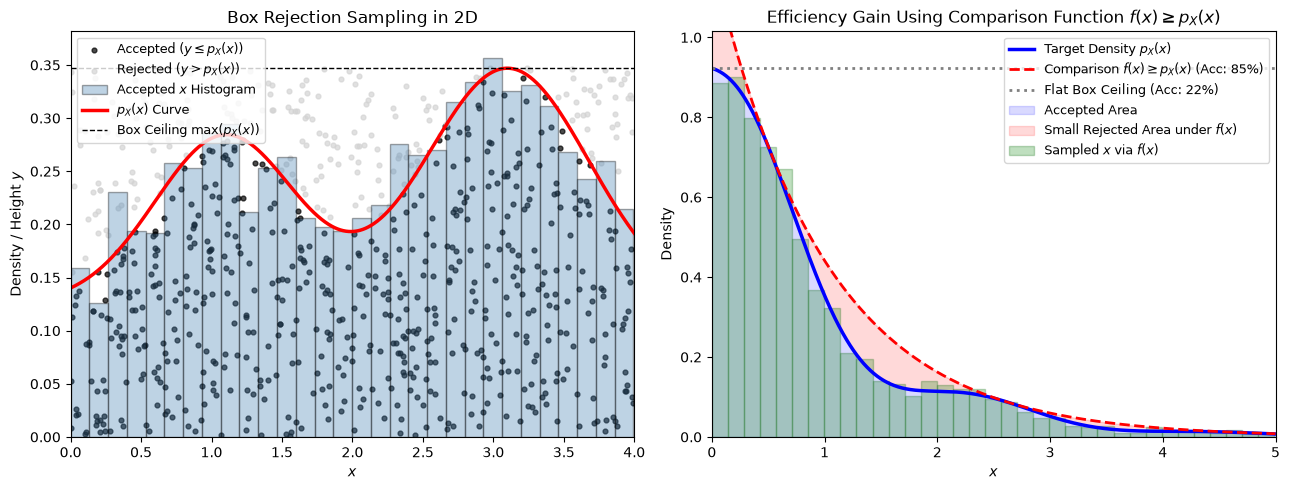

In [ ]:
from scipy.integrate import quad
rng = np.random.default_rng(52)

# =====================================================================
# Part 1: Visualizing 2D Box Rejection (Two-Peak Curve like the Article)
# Target unnormalized shape on [0, 4], normalized numerically for plotting
# =====================================================================

a, b = 0.0, 4.0
raw_p1 = lambda x: 0.4 + 0.5 * np.exp(-2.0 * (x - 1.1)**2) + 0.7 * np.exp(-1.5 * (x - 3.1)**2) # Unnormalized target density
norm_1, _ = quad(raw_p1, a, b)
p_X1 = lambda x: raw_p1(x) / norm_1

# Find max(p_X(x)) on [a, b]
x_grid1 = np.linspace(a, b, 1000)
M1 = np.max(p_X1(x_grid1))

# Throw N_trials 2D uniform darts in the box [a, b] x [0, M1]
N_trials = 5_000
x_cand = rng.uniform(a, b, N_trials)
y_cand = rng.uniform(0.0, M1, N_trials)

accepted_mask = y_cand <= p_X1(x_cand)
x_accepted = x_cand[accepted_mask]

print("--- Part 1: Double-Peak Box Rejection ---")
print(f"Total trials: {N_trials} | Accepted: {np.sum(accepted_mask)} | Acceptance Rate: {np.mean(accepted_mask)*100:.1f}%\n")

# =====================================================================
# Part 2: Sharply Peaked p_X(x) — Box vs. Comparison Function f(x)
# Target density on [0, 5]: p_X(x) = C * e^{-x} * (1 + 0.3 * sin(3x))
# Its CDF is tedious to invert, so we use Rejection Sampling!
# =====================================================================
a2, b2 = 0.0, 5.0
raw_p2 = lambda x: np.exp(-x) * (1.0 + 0.3 * np.sin(3.0 * x)) # Unnormalized target density
norm_2, _ = quad(raw_p2, a2, b2)
p_X2 = lambda x: raw_p2(x) / norm_2

x_grid2 = np.linspace(a2, b2, 1000)
M2 = np.max(p_X2(x_grid2))

# --- Method A: Simple Box Rejection on [0, 5] x [0, M2] ---
x_box = rng.uniform(a2, b2, N_trials)
y_box = rng.uniform(0.0, M2, N_trials)
acc_box = x_box[y_box <= p_X2(x_box)]
eff_box = len(acc_box) / N_trials # Acceptance efficiency for box rejection

# --- Method B: Comparison Function f(x) >= p_X(x) via Transformation Method ---
# Since (1 + 0.3*sin(3x)) <= 1.3 everywhere, we bound p_X(x) from above with:
# f(x) = (1.3 / norm_2) * e^{-x} >= p_X(x) for all x in [0, 5]
f_comp = lambda x: (1.3 / norm_2) * np.exp(-x)

# Sample x from the normalized exponential density proportional to e^{-x} on [0, 5]
# using the exact Inverse Transform formula from the previous section!
u1 = rng.uniform(0.0, 1.0, N_trials)
x_comp = -np.log(1.0 - (1.0 - np.exp(-b2)) * u1) # Inverse CDF of truncated exponential on [0, 5]

# Sample y uniformly in [0, f(x)] and accept if y <= p_X(x)
y_comp = rng.uniform(0.0, 1.0, N_trials) * f_comp(x_comp) # Sample y uniformly in [0, f(x)]
acc_comp = x_comp[y_comp <= p_X2(x_comp)] # Accepted x values using comparison function rejection
eff_comp = len(acc_comp) / N_trials # Acceptance efficiency for comparison function rejection

print("--- Part 2: Peaked Function (Box vs. Comparison Function f(x)) ---")
print(f"Box Rejection Acceptance Rate        : {eff_box*100:.1f}%")
print(f"Comparison f(x) Acceptance Rate      : {eff_comp*100:.1f}% ({eff_comp/eff_box:.1f}x more efficient!)")

# =====================================================================
# Visualization
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: 2D Dartboard & Histogram for Part 1 (show first 800 darts for clarity)
n_show = 800
ax1.scatter(x_cand[:n_show][accepted_mask[:n_show]], y_cand[:n_show][accepted_mask[:n_show]],
            color='black', s=12, alpha=0.7, label=rf'Accepted ($y \leq p_X(x)$)')
ax1.scatter(x_cand[:n_show][~accepted_mask[:n_show]], y_cand[:n_show][~accepted_mask[:n_show]],
            color='lightgray', s=12, alpha=0.7, label=rf'Rejected ($y > p_X(x)$)')
ax1.hist(x_accepted, bins=30, density=True, color='steelblue', alpha=0.35, edgecolor='black', label='Accepted $x$ Histogram')
ax1.plot(x_grid1, p_X1(x_grid1), 'r-', lw=2.5, label='$p_X(x)$ Curve')
ax1.axhline(M1, color='k', ls='--', lw=1, label=r'Box Ceiling $\max(p_X(x))$')
ax1.set_xlim(a, b)
ax1.set_ylim(0, M1 * 1.1)
ax1.set_xlabel('$x$')
ax1.set_ylabel('Density / Height $y$')
ax1.set_title('Box Rejection Sampling in 2D')
ax1.legend(loc='upper left', fontsize=9)

# Right Plot: Peaked p_X(x) with Box Ceiling vs. Comparison Function f(x)
ax2.plot(x_grid2, p_X2(x_grid2), 'b-', lw=2.5, label='Target Density $p_X(x)$')
ax2.plot(x_grid2, f_comp(x_grid2), 'r--', lw=2, label=rf'Comparison $f(x) \geq p_X(x)$ (Acc: {eff_comp*100:.0f}%)')
ax2.axhline(M2, color='gray', ls=':', lw=2, label=rf'Flat Box Ceiling (Acc: {eff_box*100:.0f}%)')
ax2.fill_between(x_grid2, 0, p_X2(x_grid2), color='blue', alpha=0.15, label=rf'Accepted Area')
ax2.fill_between(x_grid2, p_X2(x_grid2), f_comp(x_grid2), color='red', alpha=0.15, label=rf'Small Rejected Area under $f(x)$')
ax2.hist(acc_comp, bins=35, density=True, color='green', alpha=0.25, edgecolor='darkgreen', label=rf'Sampled $x$ via $f(x)$')
ax2.set_xlim(a2, b2)
ax2.set_ylim(0, M2 * 1.1)
ax2.set_xlabel('$x$')
ax2.set_ylabel('Density')
ax2.set_title(r'Efficiency Gain Using Comparison Function $f(x) \geq p_X(x)$')
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

### Importance Sampling via the Rejection Method vs. Naive Monte Carlo

When evaluating $I = \int_a^b f(x)\,dx$, if we choose an importance sampling probability density $g(x)$ ($\int_a^b g(x)\,dx = 1$) whose cumulative distribution is not easily invertible, we use the **Rejection Method** to generate the $N$ sample points $x_1, \dots, x_N \sim g(x)$:

1. **Generate Samples $x_j \sim g(x)$ via Rejection Sampling:**
   Pick uniform points $(x, y)$ in the bounding box $[a, b] \times [0, \max(g(x))]$ and accept $x$ if $y \le g(x)$ until $N$ samples $x_1, \dots, x_N$ are collected.

2. **Importance Sampling Estimator:**
   Evaluate the flattened ratio $h(x_j) = \frac{f(x_j)}{g(x_j)}$ at the accepted points:
   $$I_{\text{IS}} = \int_a^b \frac{f(x)}{g(x)} g(x)\,dx \approx \langle h \rangle \pm \sqrt{\frac{\langle h^2 \rangle - \langle h \rangle^2}{N}}, \qquad \langle h \rangle = \frac{1}{N}\sum_{j=1}^N \frac{f(x_j)}{g(x_j)}$$

3. **Naive Monte Carlo Estimator:**
   Sample $x_1, \dots, x_N \sim \text{Uniform}(a, b)$ and compute:
   $$I_{\text{naive}} \approx (b - a)\langle f \rangle \pm (b - a)\sqrt{\frac{\langle f^2 \rangle - \langle f \rangle^2}{N}}$$

Exact Integral Value: 0.382714

      N |       Naive MC ± Error |  Importance Sampling ± Error
-----------------------------------------------------------------
    100 |  0.391968 ±  0.029578 |     0.383409 ±  0.002248
   1000 |  0.391065 ±  0.009636 |     0.383083 ±  0.000722
  10000 |  0.380404 ±  0.002981 |     0.382922 ±  0.000220
 100000 |  0.382400 ±  0.000939 |     0.382757 ±  0.000069


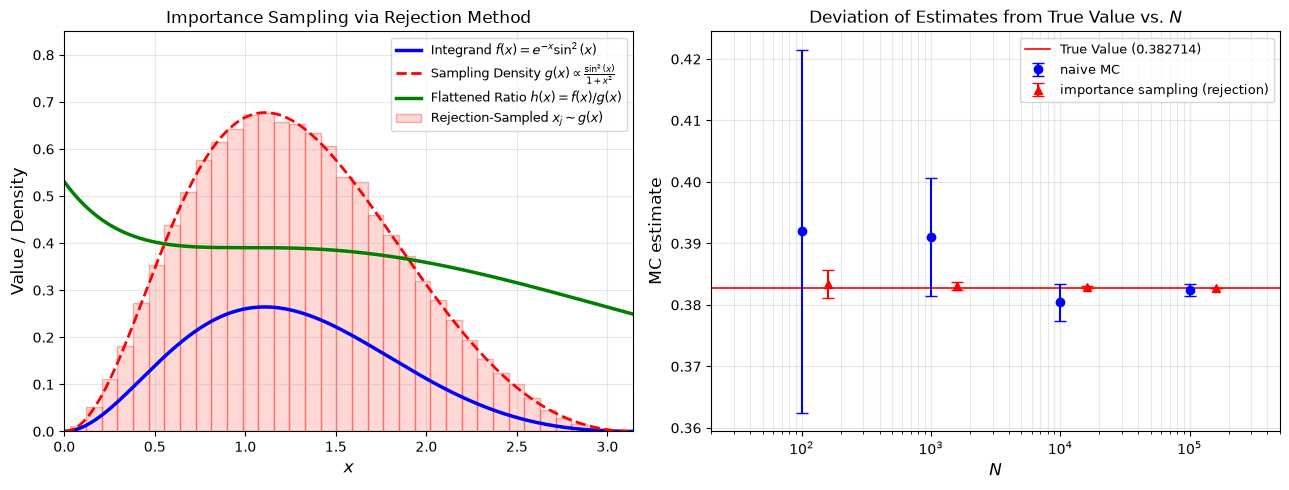

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

rng = np.random.default_rng(7)

# =====================================================================
# Target Integral: I = \int_0^\pi e^{-x} * sin^2(x) dx
# Exact Analytical Value: 2 * (1 - e^{-\pi}) / 5 ≈ 0.38271447
# =====================================================================
a, b = 0.0, np.pi

def f(x):
    """Integrand f(x) on [0, pi]."""
    return np.exp(-x) * (np.sin(x) ** 2)

exact_val = 2.0 * (1.0 - np.exp(-np.pi)) / 5.0

# ---------------------------------------------------------------------
# Importance Sampling Density g(x) Sampled via the Rejection Method
# Choose g(x) proportional to sin^2(x) / (1 + x^2) on [0, pi].
# It never hits zero where e^{-x} > 0, so h(x) = f(x)/g(x) never blows up!
# ---------------------------------------------------------------------
g_norm, _ = quad(lambda x: (np.sin(x) ** 2) / (1.0 + x**2), a, b)

def g_pdf(x):
    """Normalized importance density g(x) on [0, pi]."""
    return (np.sin(x) ** 2) / ((1.0 + x**2) * g_norm)

def h_ratio(x):
    """Flattened function h(x) = f(x) / g(x) = g_norm * e^{-x} * (1 + x^2)."""
    return g_norm * np.exp(-x) * (1.0 + x**2)

def sample_g_rejection(g_pdf, a, b, g_max, N, rng):
    """Draws N samples from g_pdf(x) using the 2D Box Rejection Method."""
    accepted = []
    while len(accepted) < N:
        batch_size = int((N - len(accepted)) * 2.5) + 100
        x_try = rng.uniform(a, b, batch_size)
        y_try = rng.uniform(0.0, g_max, batch_size)
        keep = x_try[y_try <= g_pdf(x_try)]
        accepted.extend(keep)
    return np.array(accepted[:N])

# ---------------------------------------------------------------------
# Integration Functions: Naive MC vs. Importance Sampling (Rejection)
# ---------------------------------------------------------------------
def integrate_naive_mc(f, a, b, N, rng):
    x = rng.uniform(a, b, N)
    vals = (b - a) * f(x)
    est = np.mean(vals)
    err = np.sqrt((np.mean(vals**2) - est**2) / N)
    return est, err

def integrate_importance_rejection(a, b, g_max, N, rng):
    x_imp = sample_g_rejection(g_pdf, a, b, g_max, N, rng)
    h_vals = h_ratio(x_imp)
    est = np.mean(h_vals)
    err = np.sqrt((np.mean(h_vals**2) - est**2) / N)
    return est, err, x_imp

# =====================================================================
# Run Both Methods Across N = 10^2, 10^3, 10^4, 10^5
# =====================================================================
x_grid = np.linspace(a, b, 500)
g_max = np.max(g_pdf(x_grid)) * 1.02

N_list = [10**2, 10**3, 10**4, 10**5]
naive_ests, naive_errs = [], []
imp_ests, imp_errs = [], []

print(f"Exact Integral Value: {exact_val:.6f}\n")
print(f"{'N':>7} | {'Naive MC ± Error':>22} | {'Importance Sampling ± Error':>28}")
print("-" * 65)

for N in N_list:
    est_n, err_n = integrate_naive_mc(f, a, b, N, rng)
    est_i, err_i, x_imp_last = integrate_importance_rejection(a, b, g_max, N, rng)
    
    naive_ests.append(est_n)
    naive_errs.append(err_n)
    imp_ests.append(est_i)
    imp_errs.append(err_i)
    
    print(f"{N:7d} | {est_n:9.6f} ± {err_n:9.6f} | {est_i:12.6f} ± {err_i:9.6f}")

# =====================================================================
# Plotting:
# Left Plot : Integrand f(x), Rejection-Sampled g(x), and Flattened h(x)
# Right Plot: How Estimates Deviate from the True Value vs. N
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- Left Panel: Importance Sampling Visualization ---
ax1.plot(x_grid, f(x_grid), 'b-', lw=2.5, label=r'Integrand $f(x) = e^{-x}\sin^2(x)$')
ax1.plot(x_grid, g_pdf(x_grid), 'r--', lw=2, label=r'Sampling Density $g(x) \propto \frac{\sin^2(x)}{1+x^2}$')
ax1.plot(x_grid, h_ratio(x_grid), 'g-', lw=2.5, label=r'Flattened Ratio $h(x) = f(x)/g(x)$')
ax1.hist(x_imp_last, bins=35, density=True, color='salmon', alpha=0.3, edgecolor='red',
         label=r'Rejection-Sampled $x_j \sim g(x)$')
ax1.set_xlim(a, b)
ax1.set_ylim(0, 0.85)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('Value / Density', fontsize=12)
ax1.set_title('Importance Sampling via Rejection Method')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# --- Right Panel: Estimates & Deviation from True Value vs. N ---
N_arr = np.array(N_list, dtype=float)
ax2.axhline(exact_val, color='red', lw=1.2, label=f'True Value ({exact_val:.6f})')
ax2.errorbar(N_arr, naive_ests, yerr=naive_errs, fmt='bo', capsize=4, label='naive MC')
ax2.errorbar(N_arr * 1.6, imp_ests, yerr=imp_errs, fmt='r^', capsize=4, label='importance sampling (rejection)')

ax2.set_xscale('log')
ax2.set_xlim(20, 5e5)
ax2.set_xlabel('$N$', fontsize=12)
ax2.set_ylabel('MC estimate', fontsize=12)
ax2.set_title('Deviation of Estimates from True Value vs. $N$')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

## Monte Carlo Using Stationary Stochastic Processes

For high-dimensional integrals ($D \gg 1$), the transformation and rejection methods are generally infeasible due to analytic intractability and the curse of dimensionality. Instead, we generate sample points using a **stationary stochastic process** (such as a random walk).

### Definitions
* **Stochastic Process:** A sequence of random states $X_0, X_1, X_2, \dots$ at discrete steps $t = 0, 1, 2, \dots$ where the transition to $X_t$ is governed by conditional probabilities given previous states.
* **Stationary Process:** A stochastic process whose joint probability distributions are invariant under time shifts ($t \to t + h$). Consequently:
  * **Constant Mean:** $E(X_t) = \mu$ (independent of $t$)
  * **Constant Variance:** $E((X_t - \mu)^2) = \sigma^2 = R(0)$ (independent of $t$)
* **Autocovariance $R(s)$:** Because successive steps are correlated (dependent), the covariance between two states separated by lag $s = |t - t'|$ depends only on $s$:

$$R(s) = E\big((X_k - \mu)(X_{k+|s|} - \mu)\big), \quad R(s) = R(-s) $$

  Note that $R(0) = E\big((X_k - \mu)^2\big) = \sigma^2$ : Ordinary variance
* **Autocorrelation Function $\rho(t)$:** Normalized autocovariance:
  $$\rho(t) = \frac{R(t)}{R(0)} = \frac{R(t)}{\sigma^2} , \qquad \rho(0) = 1, \quad -1 \le \rho(t) \le 1 \text{ (by Cauchy-Schwarz inequality)}$$


### Law of Large Numbers & Variance for Correlated Samples
Let $\overline{X}_N = \frac{1}{N}\sum_{k=1}^N X_k$ be the sample mean of $N$ points from a stationary stochastic process with $\sum_{s=0}^\infty |R(s)| < \infty$.

1. **Variance of the Sample Mean:** (stated without proof)
   
   $$\lim_{N \to \infty} N E\big((\overline{X}_N - \mu)^2\big) = \sum_{k=-\infty}^{\infty} R(k) = R(0) + 2\sum_{k=1}^{\infty} R(k)$$


2. **Law of Large Numbers:**
   Since $\sum_{k=-\infty}^\infty |R(k)| < \infty$, the variance of $\overline{X}_N$ vanishes as $\mathcal{O}(1/N)$ as $N \to \infty$, guaranteeing convergence in probability to the true mean $\mu$:
   $$\lim_{N \to \infty} P\left(|\overline{X}_N - \mu| \ge \varepsilon\right) = 0, \qquad \forall \quad \varepsilon > 0$$


### The $M$-Dependent Central Limit Theorem

Let $X_1, X_2, \dots, X_N$ be a stationary $M$-dependent sequence (a sequence is called $M$-dependent if points separated by more than $M$ steps ($s > M$) are completely statistically independent, meaning $X_t$ and $X_{t+s}$ are independent for lag $s > M$, so $R(h) = 0$ for $|h| > M$) of random variables with mean $E(X_t) = \mu$ and finite variance.

Define the sample mean $\overline{X}_N = \frac{1}{N}\sum_{i=1}^N X_i$ and the effective asymptotic variance $\sigma^2$ (which is independent of index $i$ by stationarity):

$$\sigma^2 = \sum_{h=-M}^{M} R(h) = R(0) + 2\sum_{h=1}^{M} R(h) = E\big((X_1 - \mu)^2\big) + 2\sum_{h=1}^{M} E\big((X_1 - \mu)(X_{1+h} - \mu)\big)$$

In practice, since the true expectations $E(\dots)$ and true mean $\mu$ are unknown, we estimate $\sigma^2$ from the $N$ samples by replacing $E(\dots)$ with sample averages over all valid pairs:

$$\hat{\sigma}^2 = \frac{1}{N} \sum_{i=1}^N (X_i - \overline{X}_N)^2 + 2\sum_{h=1}^M \frac{1}{N - h} \sum_{i=1}^{N-h} (X_i - \overline{X}_N)(X_{i+h} - \overline{X}_N)$$

In the 2nd term we divide by $N - h$ as there are only $N - h$ valid pairs $(X_i, X_{i+h})$ separated by lag $h$ in a sample of size $N$.

Then the standardized deviation $\frac{\overline{X}_N - \mu}{\sigma / \sqrt{N}} = \frac{X_1 + \dots + X_N - N\mu}{\sigma\sqrt{N}}$ converges in distribution to a standard normal variable $\mathcal{N}(0, 1)$:

$$\lim_{N \to \infty} P\left(\frac{a\sigma}{\sqrt{N}} < (\overline{X}_N - \mu) < \frac{b\sigma}{\sqrt{N}}\right) = \frac{1}{\sqrt{2\pi}} \int_a^b e^{-x^2/2}\,dx$$


### Master Formula for Monte Carlo Integration with Correlated Samples
When $N$ sample points $\vec{x}_1, \dots, \vec{x}_N$ are generated by a stationary stochastic process with normalized equilibrium density $p(\vec{x})$ ($\int_{\mathcal{V}} p(\vec{x})\,d^D x = 1$) and absolutely summable autocovariance ($\sum_{h=0}^\infty |R_h(f)| < \infty$), the integral and its $1\sigma$ statistical error are given by:

$$ \boxed{ \int_{\mathcal{V}} p(\vec{x}) f(\vec{x})\,d^D x \approx \langle f \rangle \pm \sqrt{\frac{R_0(f) + 2\sum_{h \ge 1} R_h(f)}{N}} }$$

* **Sample Mean:**
  $$\langle f \rangle \equiv \frac{1}{N} \sum_{i=1}^N f(\vec{x}_i)$$
* **Sample Autocovariance at Lag $h$ (averaged over all $N - h$ pairs Separated by $h$ Steps):**
  $$R_h(f) \equiv \frac{1}{N - h} \sum_{i=1}^{N - h} \big(f(\vec{x}_i) - \langle f \rangle\big)\big(f(\vec{x}_{i+h}) - \langle f \rangle\big)$$
  $$ R_0(f) = \frac{1}{N}\sum_{i=1}^N \big(f(\vec{x}_i) - \langle f \rangle\big)^2 $$
* **Special Case ($h = 0$):** $R_0(f) = \frac{1}{N}\sum_{i=1}^N \big(f(\vec{x}_i) - \langle f \rangle\big)^2 = \langle f^2 \rangle - \langle f \rangle^2$ is the naive variance.

## Markov Chains and Transition Matrices

### Definition of a Markov Chain
A **Markov chain** is a discrete-time stochastic process over $R$ states $s_1, s_2, \dots, s_R$ where the probability of moving to the next state depends **only on the current state** (the *memoryless* or *Markov* property):

$$P(X_{t} = s_j \mid X_0, X_1, \dots, X_{t-1} = s_i) = P(X_{t} = s_j \mid X_{t-1} = s_i) = p_{ij}$$

* **Transition Probabilities ($p_{ij}$):** The probability of transitioning from state $s_i$ to state $s_j$ in a single step.
* **Time Homogeneous Chain:** The transition probabilities $p_{ij}$ are constant and independent of the step index $t$.
* **Transition (Markov) Matrix ($\mathbf{P}$):** The $R \times R$ real square matrix whose $(i, j)$ entry is $p_{ij}$.



### Fundamental Properties of Markov Matrices
1. **Non-Negativity:** Every entry satisfies $p_{ij} \ge 0$.
2. **Row Normalization:** Because the system must transition from state $s_i$ to *some* state $s_j$ at the next step, each row sums to unity:

$$\sum_{j=1}^R p_{ij} = 1$$

3. **Doubly Stochastic Matrix:** A Markov matrix whose columns *also* sum to unity ($\sum_{i=1}^R p_{ij} = 1$).
4. **Closure Under Multiplication:** If $\mathbf{P}_1$ and $\mathbf{P}_2$ are Markov matrices, their product $\mathbf{P}_1 \mathbf{P}_2$ is also a Markov matrix (its entries are non-negative and its rows sum to $1$).
5. **Unit Eigenvalue ($\lambda = 1$):** Every Markov matrix has at least one eigenvalue equal to $1$, since the column vector of all ones $\mathbf{v} = (1, 1, \dots, 1)^T$ satisfies $(\mathbf{P}\mathbf{v})_i = \sum_{j=1}^R p_{ij} = 1$, so $\mathbf{P}\mathbf{v} = 1\mathbf{v}$.
6. **Bounded Eigenvalues ($|\lambda| \le 1$):** Every eigenvalue $\lambda$ of a Markov matrix satisfies $|\lambda| \le 1$.
   * *Proof:* Let $\mathbf{P}\mathbf{v} = \lambda \mathbf{v}$ and let $|v_k| \ge |v_j|$ for all $j$. Then, using generalised triangle inequality for complex numbers $\left|\sum_{k}z_k \right| \le \sum_k |z_k|:$

$$|\lambda v_k| = |\lambda||v_k| = \left|\sum_{j=1}^R p_{kj} v_j\right| \le \sum_{j=1}^R | p_{kj} v_j|  \le \sum_{j=1}^R p_{kj}|v_j| \le |v_k|\sum_{j=1}^R p_{kj} = |v_k| \implies |\lambda| \le 1$$



### Review of Eigenvalues and Left/Right Eigenvectors
For a real $R \times R$ square matrix $\mathbf{P}$:
* **Right Eigenvector:** A nonzero column vector $\mathbf{v}$ satisfying $\mathbf{P}\mathbf{v} = \lambda\mathbf{v}$.
* **Left Eigenvector:** A nonzero vector $\mathbf{v}$ satisfying $\mathbf{v}^T\mathbf{P} = \lambda\mathbf{v}^T$ (equivalently, $\mathbf{P}^T\mathbf{v} = \lambda\mathbf{v}$).
* **Spectrum Properties:**
  * $\mathbf{P}$ has $R$ complex eigenvalues (counting multiplicity), which are either real or occur in complex conjugate pairs.
  * $\mathbf{P}$ and its transpose $\mathbf{P}^T$ share the exact same eigenvalues since $\det(\mathbf{P} - \lambda\mathbf{I}) = \det(\mathbf{P}^T - \lambda\mathbf{I})$.
  * Eigenvectors corresponding to distinct eigenvalues are linearly independent; $R$ linearly independent eigenvectors are guaranteed if all $R$ eigenvalues are distinct.

### Multi-Step Transitions & Conditions for Ergodicity

#### $n$-Step Transition Probabilities
The $(i, j)$ element of the $n$-th matrix power $\mathbf{P}^n$, denoted $p_{ij}^{(n)}$, gives the probability that a Markov chain starting in state $s_i$ will be in state $s_j$ after $n$ steps.
Given an initial probability distribution vector $\mathbf{u}$ over the states, the probability distribution after $n$ steps is:

$$\mathbf{u}^{(n)T} = \mathbf{u}^T \mathbf{P}^n, \qquad u_j^{(n)} = \sum_{i=1}^R u_i p_{ij}^{(n)}$$

#### Essential Properties of Markov Chain States
To guarantee that $\mathbf{u}^{(n)T} = \mathbf{u}^T \mathbf{P}^n$ converges to a unique stationary (equilibrium) distribution as $n \to \infty$, the Markov chain must satisfy three conditions (collectively known as **ergodicity**):

1. **Irreducibility (Single Communicating Class):**
   * State $s_j$ is *accessible* from $s_i$ ($s_i \to s_j$) if $p_{ij}^{(n)} > 0$ for some finite $n$.
   * Two states *communicate* ($s_i \leftrightarrow s_j$) if $s_i \to s_j$ and $s_j \to s_i$. A set of mutually communicating states forms a **class**.
   * A Markov chain is **irreducible** if every state can reach every other state ($p_{ij}^{(n)} > 0$ for some $n$), meaning all states belong to a **single communicating class**.

2. **Positive Recurrence:**
   * Let $f_{ii}$ be the probability that the chain starting in state $s_i$ ever returns to $s_i$, and let $\mu_i$ be the **mean recurrence time** (expected number of steps to return to $s_i$).
   * **Transient State ($f_{ii} < 1$):** Has a non-zero probability of never returning; visited only a finite number of times ($\sum_{n=1}^\infty p_{ii}^{(n)} < \infty$).
   * **Recurrent State ($f_{ii} = 1$):** Guaranteed to return infinitely often ($\sum_{n=1}^\infty p_{ii}^{(n)} = \infty$).
     * **Positive Recurrent:** Returns with a finite expected number of steps ($\mu_i < \infty$).
     * **Null Recurrent:** Guaranteed to return eventually, but the expected return time is infinite ($\mu_i = \infty$).

3. **Aperiodicity:**
   * The **period** $d(i)$ of state $s_i$ is the greatest common divisor (gcd) of all step counts $n \ge 1$ for which $p_{ii}^{(n)} > 0$.
   * **Periodic State ($d(i) > 1$):** Can only return to $s_i$ at multiples of $d(i)$ steps (cycles between mutually exclusive subsets).
   * **Aperiodic State ($d(i) = 1$):** No cyclic restriction on return times. *(Note: Any state with a non-zero probability of remaining in place on a single step, $p_{ii} > 0$, is automatically aperiodic with $d(i) = 1$.)*

> **Class Solidarity Theorem:** All states within a communicating class share the exact same recurrence type and period. Thus, in an **irreducible** Markov chain, if one state is positive recurrent and aperiodic, **all** states in the chain are positive recurrent and aperiodic.

### Asymptotic Behavior & Stationary (Equilibrium) Distribution

#### Finite Irreducible Chains
In an irreducible Markov chain with a finite number of states $R$:
* It is possible to transition from any state to any other state in at most $R - 1$ steps.
* There are **no null recurrent states**, and it is impossible for all states to be transient (hence all states are automatically **positive recurrent**).


#### Asymptotic Limit of $n$-Step Transition Probabilities ($n \to \infty$)
For an aperiodic, positive recurrent state $s_j$ with mean recurrence time $\mu_j$, the long-time probability of being in state $s_j$ after $n$ steps is:

$$\lim_{n \to \infty} p_{jj}^{(n)} = \frac{1}{\mu_j}, \qquad \lim_{n \to \infty} p_{ij}^{(n)} = f_{ij}\frac{1}{\mu_j}$$

*(For transient or null recurrent states, $\lim_{n \to \infty} p_{ij}^{(n)} = 0$.)*

In an **irreducible, aperiodic, positive recurrent (ergodic)** chain, the chain is guaranteed to visit every state ($f_{ij} = 1$), so:

$$\lim_{n \to \infty} p_{ij}^{(n)} = \frac{1}{\mu_j}$$

* **Physical Meaning (Thermalization):** As $n \to \infty$, the probability $p_{ij}^{(n)}$ of finding the system in state $s_j$ becomes **completely independent of the starting state $s_i$**, converging to the inverse of the mean recurrence time $u_j$.


#### Stationary (Invariant) Distribution & Equilibrium
A probability vector $\mathbf{w}$ (with $w_j \ge 0$ and $\sum_j w_j = 1$) is called **stationary**, **invariant**, or a **fixed-point** of the Markov chain if it is a left eigenvector of $\mathbf{P}$ with eigenvalue $\lambda = 1$:

$$\mathbf{w}^T = \mathbf{w}^T \mathbf{P} \quad \Longrightarrow \quad \mathbf{w}^T = \mathbf{w}^T \mathbf{P}^n$$

When a Markov chain reaches the probability distribution $\mathbf{w}$, the distribution remains unchanged under further steps and the system is said to be in **equilibrium** (thermalized).

### Fundamental Limit Theorem for Irreducible Markov Chains (Ergodic Theorem)

**Theorem:** An *irreducible*, *aperiodic* Markov chain with transition matrix $\mathbf{P}$ has a **stationary distribution** $\mathbf{w}$ satisfying:

$$w_j > 0, \qquad \sum_j w_j = 1, \qquad \mathbf{w}^T = \mathbf{w}^T \mathbf{P}$$

**if and only if** all of its states are **positive recurrent**. Furthermore, this stationary distribution $\mathbf{w}$ is **unique** and identical to the limiting distribution independent of the initial state $s_i$:

$$w_j = \lim_{n \to \infty} p_{ij}^{(n)}$$

#### Summary of the Three Conditions:
* **Positive Recurrence** $\implies$ guarantees the **existence** of at least one invariant probability vector $\mathbf{w}$.
* **Irreducibility** $\implies$ guarantees the **uniqueness** of the invariant probability vector $\mathbf{w}$.
* **Aperiodicity** $\implies$ guarantees that the **limiting distribution** ($\lim_{n\to\infty} p_{ij}^{(n)}$) converges to the invariant distribution $\mathbf{w}$.


#### Ergodic $3 \times 3$ Markov Chain Example

Consider the $3 \times 3$ transition matrix:

$$\mathbf{P} = \begin{bmatrix} 3/4 & 1/4 & 0 \\ 0 & 2/3 & 1/3 \\ 1/4 & 1/4 & 1/2 \end{bmatrix}$$

1. **Irreducibility & Aperiodicity:** Since $\mathbf{P}^2$ has strictly positive entries ($p_{ij}^{(2)} > 0$ for all $i, j$) and the diagonal entries satisfy $p_{ii} > 0$, this finite Markov chain is irreducible, aperiodic, and positive recurrent.
2. **Eigenvalues & Eigenvectors:**
   The eigenvalues of $\mathbf{P}$ are $\lambda_1 = 1$, $\lambda_2 = \frac{1}{2}$, and $\lambda_3 = \frac{5}{12}$. The unnormalized right ($\mathbf{P}\mathbf{v} = \lambda\mathbf{v}$) and left ($\mathbf{v}^T\mathbf{P} = \lambda\mathbf{v}^T$) eigenvectors are:

$$\text{right: } \underbrace{\begin{bmatrix} 1 \\ 1 \\ 1 \end{bmatrix}}_{\lambda = 1}, \quad \underbrace{\begin{bmatrix} 2 \\ -2 \\ 1 \end{bmatrix}}_{\lambda = 1/2}, \quad \underbrace{\begin{bmatrix} 3 \\ -4 \\ 3 \end{bmatrix}}_{\lambda = 5/12} \qquad\qquad \text{left: } \underbrace{\begin{bmatrix} 2 \\ 3 \\ 2 \end{bmatrix}}_{\lambda = 1}, \quad \underbrace{\begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix}}_{\lambda = 1/2}, \quad \underbrace{\begin{bmatrix} -3 \\ -1 \\ 4 \end{bmatrix}}_{\lambda = 5/12}$$

3. **Stationary Distribution $\mathbf{w}$ and Limiting Matrix $\lim_{n\to\infty} \mathbf{P}^n$:**
   Normalizing the $\lambda = 1$ left eigenvector $\begin{bmatrix} 2 & 3 & 2 \end{bmatrix}^T$ so that its components sum to $1$ ($2 + 3 + 2 = 7$) yields the unique stationary distribution $\mathbf{w}$. As $n \to \infty$, the sub-leading eigenvalue modes $(1/2)^n \to 0$ and $(5/12)^n \to 0$ vanish, and every row of $\mathbf{P}^n$ converges to $\mathbf{w}^T$:

$$\mathbf{w} = \frac{1}{7}\begin{bmatrix} 2 \\ 3 \\ 2 \end{bmatrix}, \qquad \lim_{n \to \infty} \mathbf{P}^n = \mathbf{W} = \frac{1}{7}\begin{bmatrix} 2 & 3 & 2 \\ 2 & 3 & 2 \\ 2 & 3 & 2 \end{bmatrix}$$

P^2 (all entries > 0, confirming irreducibility):
 [[0.5625 0.3542 0.0833]
 [0.0833 0.5278 0.3889]
 [0.3125 0.3542 0.3333]]

Eigenvalues of P      : [1.      +0.j 0.5     +0.j 0.416667+0.j]
Exact [1, 1/2, 5/12]  : [1.       0.5      0.416667]

Stationary distribution w (normalized left eigenvector for lambda=1):
Numerical w           : [0.285714 0.428571 0.285714]
Exact (1/7)*[2, 3, 2] : [0.285714 0.428571 0.285714]

Limiting Matrix P^50 (every row equals w^T):
 [[0.285714 0.428571 0.285714]
 [0.285714 0.428571 0.285714]
 [0.285714 0.428571 0.285714]]


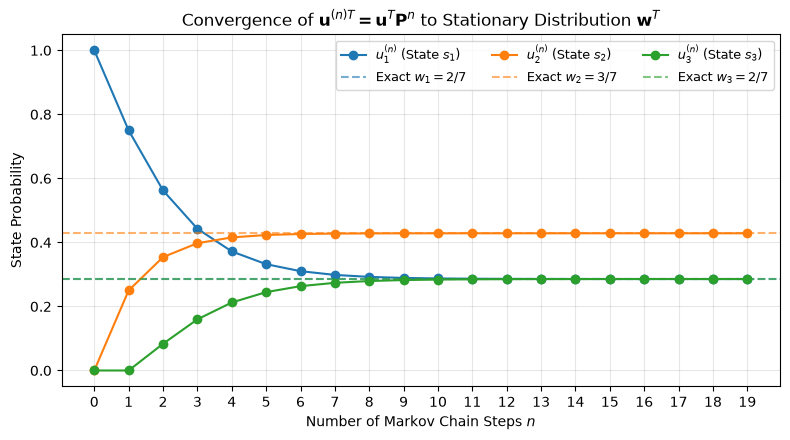

In [2]:
# implementing the Markov Chain example from the article

import numpy as np
import matplotlib.pyplot as plt

# 1. Define the 3x3 transition matrix P from the article
P = np.array([
    [3/4, 1/4, 0.0],
    [0.0, 2/3, 1/3],
    [1/4, 1/4, 1/2]
])

# 2. Check Irreducibility: P^2 has all strictly positive entries (> 0)
P2 = np.linalg.matrix_power(P, 2)
print("P^2 (all entries > 0, confirming irreducibility):\n", np.round(P2, 4))

# 3. Eigenvalues and Left Eigenvectors (solve P^T v = lambda v)
eigvals, left_eigvecs = np.linalg.eig(P.T)
print("\nEigenvalues of P      :", np.round(eigvals, 6))
print("Exact [1, 1/2, 5/12]  :", np.round([1.0, 1/2, 5/12], 6))

# Extract and normalize the left eigenvector for lambda = 1
idx_one = np.argmin(np.abs(eigvals - 1.0)) # argmin returns the index of the eigenvalue closest to 1.0
w = np.real(left_eigvecs[:, idx_one])
w = w / np.sum(w)  # Normalize so sum(w_j) = 1

print("\nStationary distribution w (normalized left eigenvector for lambda=1):")
print("Numerical w           :", np.round(w, 6))
print("Exact (1/7)*[2, 3, 2] :", np.round(np.array([2, 3, 2]) / 7, 6))

# 4. Verify limiting matrix lim_{n -> inf} P^n = W
P_50 = np.linalg.matrix_power(P, 50)
print("\nLimiting Matrix P^50 (every row equals w^T):\n", np.round(P_50, 6))

# 5. Plot Thermalization: Convergence of u^(n)T = u^T P^n to w^T
# Start entirely in state s_1: u^(0) = [1, 0, 0]
u_init = np.array([1.0, 0.0, 0.0])
steps = np.arange(0, 20)
u_history = np.array([u_init @ np.linalg.matrix_power(P, n) for n in steps])

plt.figure(figsize=(8, 4.5))
colors = ['tab:blue', 'tab:orange', 'tab:green']
exact_w = [2/7, 3/7, 2/7]

for j in range(3):
    plt.plot(steps, u_history[:, j], 'o-', color=colors[j], label=rf'$u_{j+1}^{{(n)}}$ (State $s_{j+1}$)')
    plt.axhline(exact_w[j], color=colors[j], ls='--', alpha=0.6, label=rf'Exact $w_{j+1} = {int(exact_w[j]*7)}/7$')

plt.xlabel('Number of Markov Chain Steps $n$')
plt.ylabel('State Probability')
plt.title(r'Convergence of $\mathbf{u}^{(n)T} = \mathbf{u}^T \mathbf{P}^n$ to Stationary Distribution $\mathbf{w}^T$')
plt.xticks(steps)
plt.legend(ncol=3, fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**The uniqueness of the stationary vector $w$ and its
coincidence with the limiting vector $u^{(n)}$ make ergodic
Markov chains especially useful for Monte Carlo applications.**

### Thermalization, Detailed Balance, and Autocorrelation

#### Equilibrium and Thermalization
* **Equilibrium:** A Markov chain is in equilibrium if its probability distribution matches the stationary fixed-point vector $\mathbf{w}$ (i.e., $\mathbf{w}^T \mathbf{P} = \mathbf{w}^T$). Once in equilibrium, the probability of finding the system in state $s_j$ remains fixed at $w_j$ for all subsequent steps.
* **Thermalization (Burn-in):** The process of bringing the chain into equilibrium from an arbitrary random starting distribution. Because an ergodic Markov chain is guaranteed to converge to $\mathbf{w}$, we run the chain for an initial "thermalization" period and discard these early non-equilibrium steps.

#### Detailed Balance (Reversibility)
An ergodic Markov chain is **reversible** if it satisfies the **detailed balance** condition:
$$w_i p_{ij} = w_j p_{ji}$$
This means the probability of being in state $s_i$ and transitioning to $s_j$ is identical to being in state $s_j$ and transitioning to $s_i$. 
* **The Golden Rule of MCMC:** Enforcing detailed balance mathematically guarantees that $\mathbf{w}$ is the stationary distribution of the transition matrix $\mathbf{P}$. Summing over all possible destination states $j$ yields:
  $$\sum_j w_j p_{ji} = \sum_j w_i p_{ij} = w_i \sum_j p_{ij} = w_i$$
  which is exactly the fixed-point condition $\mathbf{w}^T \mathbf{P} = \mathbf{w}^T$.

#### Autocorrelation of Observables
In an equilibrium Markov chain, successive measurements of an observable $O_i$ are statistically dependent (autocorrelated). The normalized autocorrelation function for a time lag $\tau$ is:
$$\rho(\tau) = \frac{\langle O_i O_{i+\tau} \rangle - \langle O_i \rangle^2}{\langle O_i^2 \rangle - \langle O_i \rangle^2}$$
* $\rho(\tau) \approx 1$ indicates highly correlated samples, while $\rho(\tau) \approx 0$ indicates independent samples.
* **Practical Mitigation:** Because autocorrelation generally decreases as the step separation $\tau$ increases, Monte Carlo practitioners often **skip** a predetermined number of Markov steps between measurements to reduce data correlation and computational measurement overhead.

## The Metropolis-Hastings Method

To evaluate expectation values of observables $\langle O \rangle = \int O(\phi)\pi(\phi)\mathcal{D}\phi$ in Euclidean path integrals, we need to sample field configurations $\phi$ from the Boltzmann-weighted probability density:

$$\pi(\phi) = \frac{e^{-S[\phi]/\hbar}}{\int \mathcal{D}\phi'\, e^{-S[\phi']/\hbar}} = Z^{-1} e^{-S[\phi]/\hbar}$$

where $S[\phi]$ is the real-valued Euclidean action and $Z$ is the (generally intractable) partition function normalization.


### The Algorithm
Using quantum mechanical arrow notation where $\widetilde{\phi} \leftarrow \phi$ denotes a transition from current state $\phi$ to new state $\widetilde{\phi}$, we choose an auxiliary **proposal density** $R(\widetilde{\phi} \leftarrow \phi)$ (which is normalized, easy to sample, and can be evaluated for all $\phi, \widetilde{\phi}$).

At each Markov step:
1. **Propose:** Sample a candidate state $\widetilde{\phi}$ from $R(\widetilde{\phi} \leftarrow \phi)$.
2. **Accept/Reject:** Accept the candidate $\widetilde{\phi}$ with **acceptance probability**:

$$P_{\text{acc}}(\widetilde{\phi} \leftarrow \phi) = \min\left(1, \frac{R(\phi \leftarrow \widetilde{\phi})\,\pi(\widetilde{\phi})}{R(\widetilde{\phi} \leftarrow \phi)\,\pi(\phi)}\right)$$

---

**Intuitive Guide to the Metropolis-Hastings Acceptance Formula:**

At first glance, the $\min(1, \dots)$ function seems arbitrary. Here is the physical and mathematical intuition for why it must look exactly like this.

**The "Water Tank" Analogy for Detailed Balance (Probability Flux):**
Imagine the Markov states as a vast network of water tanks, where the "water level" represents the target probability $\pi(\phi)$. For the system to be in equilibrium, the water level in every tank must remain perfectly constant. 

**Detailed Balance** achieves this by requiring that the exact volume of water flowing from Tank A to Tank B is perfectly matched by the volume flowing from Tank B back to Tank A:
$$\text{Flux(A} \to \text{B)} = \text{Flux(B} \to \text{A)}$$
$$P(\text{A} \to \text{B})\pi(\text{A}) = P(\text{B} \to \text{A})\pi(\text{B})$$

**Why the `min()` Function? (Maximizing Efficiency):**
The total transition probability $P$ is the probability of *proposing* a move ($R$) multiplied by the probability of *accepting* it ($P_{\text{acc}}$). If we rearrange the Detailed Balance equation to isolate the acceptance probabilities, we get a strict ratio (let's call it $r$):
$$ P_{\text{acc}}(\text{A} \to \text{B}) R(\text{A} \to \text{B}) \pi(\text{A}) = P_{\text{acc}}(\text{B} \to \text{A}) R(\text{B} \to \text{A}) \pi(\text{B})  $$

$$ \frac{P_{\text{acc}}(\text{forward})}{P_{\text{acc}}(\text{backward})} = \frac{R(\text{backward})\pi(\text{B})}{R(\text{forward})\pi(\text{A})} \equiv r$$

Suppose the math tells us the ratio is $r = 3$. This means our forward acceptance probability must be exactly $3\times$ larger than our backward acceptance probability.
* We *could* choose $P_{\text{acc}}(\text{forward}) = 0.3$ and $P_{\text{acc}}(\text{backward}) = 0.1$.
* But rejecting steps wastes computer time! We want to accept moves as often as mathematically possible.
* To maximize efficiency without breaking the rule that probabilities cannot exceed $1$, we push the *larger* of the two values all the way up to exactly $1$. Therefore, $P_{\text{acc}}(\text{forward}) = 1$ and $P_{\text{acc}}(\text{backward}) = 1/3$.

The $\min(1, r)$ function is simply a brilliant algorithmic shortcut for this logic. It automatically sets the larger probability to $100\%$ and scales the other one perfectly to maintain detailed balance.

---

3. **Update:** If accepted, set the next state to $\widetilde{\phi}$; **if rejected, retain the current state $\phi$** as the next element in the chain.

* **Key Advantage:** Because only the ratio $\pi(\widetilde{\phi})/\pi(\phi)$ appears in $P_{\text{acc}}$, **the unknown normalization constant $Z$ completely cancels out**!

* **Symmetric Proposal (Classic Metropolis Method):** If the proposal density is symmetric, $R(\widetilde{\phi} \leftarrow \phi) = R(\phi \leftarrow \widetilde{\phi})$, the acceptance probability simplifies to:

$$P_{\text{acc}}(\widetilde{\phi} \leftarrow \phi) = \min\left(1, \frac{\pi(\widetilde{\phi})}{\pi(\phi)}\right)$$

* **Acceptance Rate Rule of Thumb:** Tune the proposal step size parameter (e.g., $\Delta$) to achieve a **$50\%\text{--}60\%$ acceptance rate** (higher acceptance $\implies$ steps are too tiny and explore slowly; lower acceptance $\implies$ too many rejected updates).


### 1D Example from the Article 
We evaluate the ratio of integrals over $(-\infty, \infty)$:

$$I = \frac{\int_{-\infty}^{\infty} g(x)h(x)\,dx}{\int_{-\infty}^{\infty} h(x)\,dx} = \int_{-\infty}^{\infty} g(x)\,\pi(x)\,dx = 0.3987452\dots$$

where $g(x) = \cos\left(\sqrt{1 + x^2}\right)$ and $h(x) = \frac{e^{-x^2}}{x^2 + 2} \ge 0$, with importance sampling density $\pi(x) = Z^{-1}h(x)$.
* **Proposal Step:** Draw $\delta \sim \text{Uniform}(-\Delta, \Delta)$ with $\Delta = 1.5$, and propose $\widetilde{x} = x + \delta$.
* **Acceptance Probability:** $P_{\text{acc}}(\widetilde{x} \leftarrow x) = \min\big(1, h(\widetilde{x})/h(x)\big)$ (never requiring $Z = \int_{-\infty}^\infty h(x)\,dx$).

Exact Integral Ratio I = 0.3987452

      N | Acceptance |   MC Estimate ± Correlated Err | Naive Uncorr Err
------------------------------------------------------------------------
     10 |      70.0% |      0.461756 ±     0.026969   |       0.020404
    100 |      65.0% |      0.363215 ±     0.052685   |       0.026730
   1000 |      55.8% |      0.379787 ±     0.014180   |       0.006633
  10000 |      56.3% |      0.400574 ±     0.003379   |       0.001803
 100000 |      55.7% |      0.399172 ±     0.001201   |       0.000584


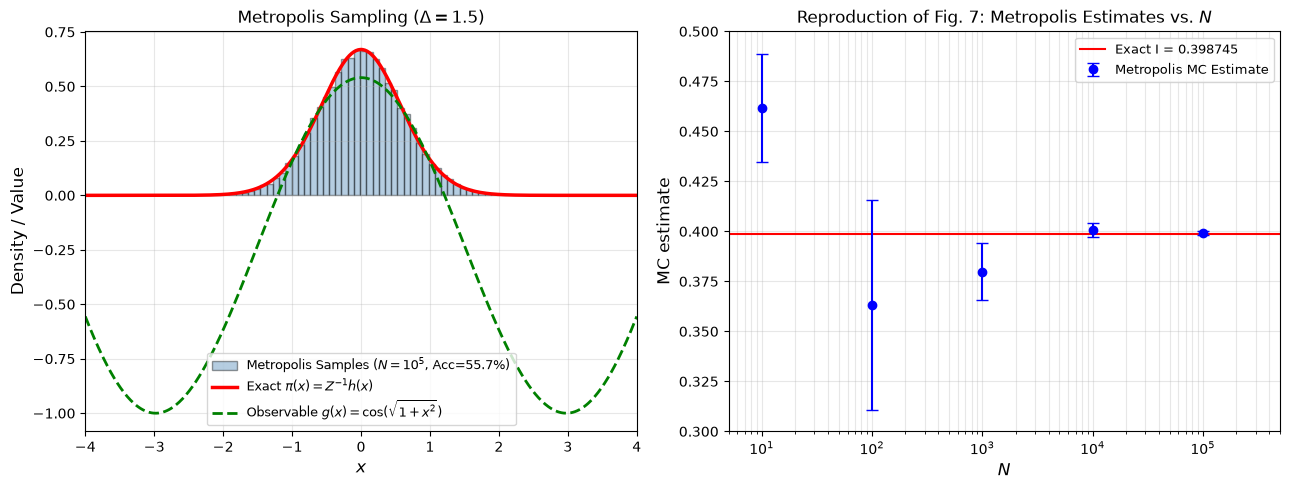

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

Rng = np.random.default_rng(1)

# =====================================================================
# 1. Define g(x) and Unnormalized Target Weight h(x) from the Article
# =====================================================================
def g(x):
    return np.cos(np.sqrt(1.0 + x**2))

def h(x):
    return np.exp(-x**2) / (x**2 + 2.0)

# Compute exact value numerically for comparison (Z is NEVER used in Metropolis!)
num_exact, _ = quad(lambda x: g(x) * h(x), -np.inf, np.inf)
den_exact, _ = quad(h, -np.inf, np.inf)
exact_I = num_exact / den_exact
print(f"Exact Integral Ratio I = {exact_I:.7f}\n")

# =====================================================================
# 2. Metropolis Algorithm Implementation
# =====================================================================
def run_metropolis(h_func, N, delta, n_therm, x0, rng):
    """
    Generates N samples from pi(x) = Z^{-1} h(x) using the Metropolis method
    with uniform symmetric proposal x_new = x + Uniform(-delta, delta).
    """
    if rng is None:
        rng = np.random.default_rng()
        
    x = x0
    h_curr = h_func(x) # Current unnormalized weight h(x)
    
    # Step A: Thermalization (burn-in) sweeps to reach equilibrium. To obtain a stationary markov chain, we discard the first n_therm samples.
    for _ in range(n_therm):
        x_prop = x + rng.uniform(-delta, delta) # Propose new x
        h_prop = h_func(x_prop)
        if rng.uniform(0.0, 1.0) < min(1.0, h_prop / h_curr): # Accept with probability min(1, h(x_tilde) / h(x)). rng.uniform(0.0, 1.0) generates a random number between 0 and 1.
            x = x_prop
            h_curr = h_prop
            
    # Step B: Production run of N steps in equilibrium
    samples = np.empty(N)
    n_accepted = 0
    
    for i in range(N):
        x_prop = x + rng.uniform(-delta, delta) # Propose new x
        h_prop = h_func(x_prop)
        
        # Accept with probability min(1, h(x_tilde) / h(x))
        if rng.uniform(0.0, 1.0) < min(1.0, h_prop / h_curr):
            x = x_prop
            h_curr = h_prop
            n_accepted += 1
        # If rejected, original x is retained!
        samples[i] = x
        
    acc_rate = n_accepted / N
    return samples, acc_rate

# =====================================================================
# 3. Correlated Error Estimator (Section 3.4 Master Formula)
# =====================================================================
def correlated_mc_estimate(obs_vals, max_lag): 
    """
    Computes <f> and its correlated Markov chain standard error:
    sqrt( (R_0 + 2 * sum_{h>=1} R_h) / N )
    """
    N = len(obs_vals) # Number of samples
    mean_val = np.mean(obs_vals) # Compute the mean of the observed values
    fluct = obs_vals - mean_val # Fluctuations from the mean
    
    R0 = np.mean(fluct**2) # Naive variance (autocovariance at lag 0)
    
    # Sum positive autocovariance lags until R_h decays to noise (or max_lag)
    sum_Rh = 0.0
    for lag in range(1, max_lag): 
        Rh = np.sum(fluct[:-lag] * fluct[lag:]) / (N - lag) # smart way to compute autocovariance at lag h. Ask AI for details if you want to understand this formula.
        if Rh <= 0:  # Standard window cutoff when autocorrelation hits zero
            break
        sum_Rh += Rh
        
    eff_var = R0 + 2.0 * sum_Rh
    err = np.sqrt(eff_var / N)
    return mean_val, err, np.sqrt(R0 / N)

# =====================================================================
# 4. Run for N = 10^2, 10^3, 10^4, 10^5 (Reproducing Fig. 7)
# =====================================================================
Delta = 1.5
N_therm = 1000
N_list = [10, 10**2, 10**3, 10**4, 10**5]
mc_ests, mc_errs = [], []

print(f"{'N':>7} | {'Acceptance':>10} | {'MC Estimate ± Correlated Err':>30} | {'Naive Uncorr Err':>16}")
print("-" * 72)

for N in N_list:
    x_chain, acc_rate = run_metropolis(h, N, delta=Delta, n_therm=N_therm, rng=Rng, x0=0.0)
    g_vals = g(x_chain)
    est, corr_err, naive_err = correlated_mc_estimate(g_vals, max_lag = N // 2)  # max_lag = N//2 is a reasonable choice. Theoretically it can be up to N-1.
    
    mc_ests.append(est)
    mc_errs.append(corr_err)
    print(f"{N:7d} | {acc_rate*100:9.1f}% | {est:13.6f} ± {corr_err:12.6f}   | {naive_err:14.6f}")

# =====================================================================
# 5. Visualization:
# Left Plot : Sampled Histogram vs Exact Normalized Density pi(x)
# Right Plot: Reproduction of Fig. 7 (MC Estimate vs N)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: Verify Markov Chain samples match pi(x) = h(x) / Z
x_grid = np.linspace(-4, 4, 500)
ax1.hist(x_chain, bins=60, density=True, color='steelblue', alpha=0.4, edgecolor='black',
         label=rf'Metropolis Samples ($N=10^5$, Acc={acc_rate*100:.1f}%)')
ax1.plot(x_grid, h(x_grid) / den_exact, 'r-', lw=2.5, label=r'Exact $\pi(x) = Z^{-1}h(x)$')
ax1.plot(x_grid, g(x_grid), 'g--', lw=2, label=r'Observable $g(x) = \cos(\sqrt{1+x^2})$')
ax1.set_xlim(-4, 4)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('Density / Value', fontsize=12)
ax1.set_title(rf'Metropolis Sampling ($\Delta = {Delta}$)')
ax1.legend(loc='lower center', fontsize=9)
ax1.grid(True, alpha=0.3)

# Right Plot: Reproduce Fig. 7 from the Article
ax2.axhline(exact_I, color='red', lw=1.5, label=f'Exact I = {exact_I:.6f}')
ax2.errorbar(N_list, mc_ests, yerr=mc_errs, fmt='bo', capsize=4, markersize=6,
             label='Metropolis MC Estimate')
ax2.set_xscale('log')
ax2.set_xlim(5, 5e5)
ax2.set_ylim(0.30, 0.50)
ax2.set_xlabel('$N$', fontsize=12)
ax2.set_ylabel('MC estimate', fontsize=12)
ax2.set_title('Reproduction of Fig. 7: Metropolis Estimates vs. $N$')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

## Simple Harmonic Oscillator

### Discretizing the Euclidean Action
The exact Euclidean (imaginary time) action for the 1D Simple Harmonic Oscillator is:

$$S[x(\tau)] = \int_{\tau_a}^{\tau_b} d\tau \left( \frac{1}{2}m\dot{x}^2 + \frac{1}{2}m\omega^2x^2 \right)$$

To evaluate this via Monte Carlo, we discretize the time interval into $N$ slices of width $\varepsilon$ (where $N\varepsilon = \tau_b - \tau_a$). Replacing the derivative with a finite difference and the position with a slice average yields the discrete action:

$$\frac{S}{\hbar} = \frac{m\varepsilon}{2\hbar} \sum_{j=0}^{N-1} \left[ \left(\frac{x_{j+1} - x_j}{\varepsilon}\right)^2 + \omega^2 \left(\frac{x_{j+1} + x_j}{2}\right)^2 \right]$$

### Non-dimensionalization
To optimize the computation, we absorb all physical constants ($m, \hbar, \omega, \varepsilon$) into dimensionless variables. By defining $\kappa = \frac{1}{4}\varepsilon^2\omega^2$, a dimensionless position $d_k = x_k \sqrt{m / (\varepsilon\hbar)}$, and finally a rescaled position $u_j = d_j\sqrt{1+\kappa}$, the action simplifies to:

$$\frac{S}{\hbar} = \left[ \sum_{j=1}^{N-1} u_j^2 \right] - g \left[ \sum_{j=0}^{N-1} u_j u_{j+1} \right]$$

where $g = \frac{1 - \kappa}{1 + \kappa}$. 
* **Boundary Conditions:** The endpoints of the path are fixed at zero ($x_a = x_b = 0$), meaning $u_0 = u_N = 0$.
* **The Markov State:** A single state in our Markov chain is an entire particle path, represented by the $(N-1)$-dimensional vector $\mathbf{u} = (u_1, u_2, \dots, u_{N-1})$.

### The Local Update Strategy
If an auxiliary proposal density attempts to change all $N-1$ components of the path $\mathbf{u}$ simultaneously, the resulting change in the action ($\Delta S$) will be too large, driving the Metropolis acceptance probability to near zero. 

To achieve a reasonable acceptance rate ($\sim 50\%$), we perform **local updates**:
1. Randomly select a single time slice $j$.
2. Propose a small change to *only* $u_j$, holding all other points fixed.
3. Accept or reject this local change using the Metropolis algorithm. 

Because each time slice is assigned an equal probability of being selected, detailed balance is preserved and the chain ergodically covers the entire integration hypervolume.

*(Note: To avoid confusion with the number of Monte Carlo measurements $N_{\text{meas}}$, the number of discrete time slices is denoted as $N_t$.)*

#### Local Path Update Algorithm ($\mathbf{u} \to \mathbf{u}^{\text{new}}$)
Because changing a single time slice $u_j \to \tilde{u}_j = u_j + \delta$ only affects terms in the action involving $u_j$ and its nearest neighbors $u_{j-1}, u_{j+1}$, the change in action $\delta S = S[\tilde{\mathbf{u}}] - S[\mathbf{u}]$ can be computed locally in $\mathcal{O}(1)$ time.

The full dimensionless action over all $N$ time slices is:

$$\frac{S}{\hbar} = \left[ \sum_{k=1}^{N-1} u_k^2 \right] - g \left[ \sum_{k=0}^{N-1} u_k u_{k+1} \right]$$

When we perform a local update at a single time slice $u_j \to \tilde{u}_j = u_j + \delta$ (while keeping all other slices fixed), almost all terms in the sums cancel out in $\delta S = S[\tilde{\mathbf{u}}] - S[\mathbf{u}]$.

* **Why both $u_{j-1}$ and $u_{j+1}$ appear:** Expanding the nearest-neighbor sum $\sum_{k=0}^{N-1} u_k u_{k+1}$ around slice $j$ shows that $u_j$ participates in **two** adjacent links—the link from $j-1$ to $j$ (when $k = j-1$) and the link from $j$ to $j+1$ (when $k = j$):

$$\sum_{k=0}^{N-1} u_k u_{k+1} = \dots + \underbrace{u_{j-1} u_j}_{k = j-1} + \underbrace{u_j u_{j+1}}_{k = j} + \dots = \dots + u_j(u_{j-1} + u_{j+1}) + \dots$$

* **Local Action $S_{\text{local}}(u_j)$:** Collecting the only terms in $S/\hbar$ that depend on $u_j$ (its self-term and its interactions with its two immediate neighbors $j-1$ and $j+1$) gives:

$$\frac{S_{\text{local}}(u_j)}{\hbar} = u_j^2 - g\, u_j(u_{j-1} + u_{j+1})$$

* **Subtracting Old from New ($\tilde{u}_j = u_j + \delta$):**

$$\frac{\delta S}{\hbar} = \frac{S_{\text{local}}(u_j + \delta) - S_{\text{local}}(u_j)}{\hbar} = \Big[(u_j + \delta)^2 - u_j^2\Big] - g\Big[(u_j + \delta) - u_j\Big](u_{j-1} + u_{j+1})$$

$$\frac{\delta S}{\hbar} = (2u_j\delta + \delta^2) - g\delta(u_{j-1} + u_{j+1}) = \delta\Big(\delta + 2u_j - g(u_{j-1} + u_{j+1})\Big)$$

**Single Sweep Procedure:**
1. **Select Slice:** Randomly choose an interior time-slice index $j \in \{1, 2, \dots, N_t - 1\}$ with equal probability.
2. **Propose Shift:** Draw a uniform random shift $\delta \in [-\Delta, \Delta]$ and propose $\tilde{u}_j = u_j + \delta$.
3. **Compute Local $\delta S$:** Evaluate $\delta S / \hbar = \delta(\delta + 2u_j - g(u_{j-1} + u_{j+1}))$.
4. **Accept/Reject:** Since the uniform proposal is symmetric ($R(\tilde{u}_j \leftarrow u_j) = R(u_j \leftarrow \tilde{u}_j)$), accept $u_j^{\text{new}} = \tilde{u}_j$ with probability:
   $$P_{\text{acc}} = \min\left(1, e^{-\delta S / \hbar}\right)$$
   If rejected, retain the old value $u_j^{\text{new}} = u_j$.
5. **Complete Sweep:** Repeat steps (1)–(4) $N_t$ times to constitute **one updating sweep** across the path.


#### Initialization, Thermalization, and Tuning Parameters
* **Initial Configuration:**
  * **Cold Start:** Set $u_j = 0$ for all $j$ (completely ordered, ground-like path).
  * **Hot Start:** Set $u_j$ to random values for all $j$ (disordered, high-action path).
* **Thermalization ($N_{\text{therm}}$):** Evolve the path for $N_{\text{therm}}$ sweeps while monitoring simple observables until the chain reaches equilibrium (its stationary fixed point) before taking measurements.
* **The Four Simulation Parameters:**
  1. **$\varepsilon$ (Lattice Spacing):** Chosen small enough that discretization errors are negligible (e.g., $\omega\varepsilon = 0.25$, $N_t = 1000$).
  2. **$\Delta$ (Proposal Width):** Tuned to achieve an acceptance rate around $50\%\text{--}60\%$ (e.g., $\Delta = 1.5$ for $\omega\varepsilon = 0.25$).
  3. **$N_{\text{sweeps}}$ (Skip Between Measurements):** Number of sweeps skipped between successive measurements to reduce autocorrelations (e.g., monitoring the two-point correlator $\langle u(\tau_0 + 5)u(\tau_0)\rangle$ shows $\sim 100$ sweeps reduces autocorrelation to $\approx 0.1$).
  4. **$N_{\text{meas}}$ (Total Measurements):** Chosen large enough to achieve the desired statistical precision.

### Glossary of the Four "$N$" Parameters in Path Integral MCMC

| Symbol | Name | Meaning in the Simulation | Typical Value |
| :--- | :--- | :--- | :--- |
| **$N_t$** | **Number of Time Slices** | How many discrete points make up **one single path** $\mathbf{u} = (u_1, \dots, u_{N_t-1})$. Updating $N_t$ random points equals **1 sweep**. | $1000$ |
| **$N_{\text{therm}}$** | **Thermalization Sweeps** | Number of initial "warm-up" sweeps discarded at the start of the run so the path forgets its artificial initial state (hot/cold start) and reaches equilibrium. | $200\text{--}1000$ |
| **$N_{\text{sweeps}}$** | **Sweeps Between Measurements** | Number of sweeps skipped *between* saved measurements so successive paths are decorrelated (low autocorrelation). | $20\text{--}100$ |
| **$N_{\text{meas}}$** | **Number of Measurements** | Total number of decorrelated path configurations saved and averaged over to compute $\langle O \rangle \pm \sigma / \sqrt{N_{\text{meas}}}$. | $10^3\text{--}10^5$ |

### Sequential vs. Random Sweeps & Two-Point Correlation Functions

#### Sequential Sweeps vs. Random Sweeps
* **Random Sweeps:** Choosing time slices $j \in \{1, \dots, N_t - 1\}$ at random with equal probability preserves **detailed balance** at every single local update (with identical transition matrix $\mathbf{P}$), but requires $N_t$ extra random number calls per sweep.
* **Sequential Sweeps:** Sweeping through the lattice in order ($j = 1, 2, \dots, N_t - 1$) requires fewer random number calls and is computationally faster.
  * **Loss of Detailed Balance, Preservation of Fixed Point:** Sequential updating violates detailed balance because forward sweeps ($1 \to N_t-1$) and reverse sweeps ($N_t-1 \to 1$) do not occur with equal probability. However, because each individual slice update matrix $\mathbf{P}_j$ leaves the target distribution $\mathbf{w}$ invariant ($\mathbf{w}^T \mathbf{P}_j = \mathbf{w}^T$), the product matrix for a full sweep $\mathbf{P}_{\text{sweep}} = \mathbf{P}_1 \mathbf{P}_2 \cdots \mathbf{P}_{N_t-1}$ still satisfies the **fixed-point condition**:
    $$\mathbf{w}^T \mathbf{P}_{\text{sweep}} = (\mathbf{w}^T \mathbf{P}_1)\mathbf{P}_2 \cdots \mathbf{P}_{N_t-1} = \mathbf{w}^T$$
  * Furthermore, because $\mathbf{P}_{\text{sweep}}$ is identical from sweep to sweep, all Markov chain limit theorems apply at the sweep level, and sequential sweeps slightly improve (reduce) autocorrelations compared to random sweeps (Fig. 8, right).


#### Two-Point Correlation Function $\langle u(\tau_0 + \tau) u(\tau_0) \rangle$ (Figs. 8–10)
To study physical correlations and monitor autocorrelation in the Simple Harmonic Oscillator ($\omega\varepsilon = 0.25$, $N_t = 1000$, $\Delta = 1.5$), we measure the **two-point correlation function** (propagator):

$$C(\tau) = \langle u(\tau_0 + \tau)\, u(\tau_0) \rangle$$

where $\tau_0$ is chosen in the bulk interior region of the path (far from the fixed boundaries $u_0 = u_{N_t} = 0$) and averaged over multiple interior $\tau_0$ slices to improve statistics.

* **Exact Analytical Result on the Lattice (for $N_t \gg 1$):**
  For the Gaussian action $\frac{S}{\hbar} = \sum u_j^2 - g \sum u_j u_{j+1}$ with $\sqrt{\kappa} = \frac{1}{2}\omega\varepsilon$ and $g = \frac{1-\kappa}{1+\kappa}$, inverting the tridiagonal quadratic form yields the exact discrete propagator as a function of integer slice separation $n = \tau / \varepsilon$:

$$ \langle u(\tau_0 + n\varepsilon)\, u(\tau_0) \rangle_{\text{exact}} = \frac{1 + \kappa}{4\sqrt{\kappa}} \left( \frac{1 - \sqrt{\kappa}}{1 + \sqrt{\kappa}} \right)^n$$

  For $\omega\varepsilon = 0.25$ ($\sqrt{\kappa} = 0.125$, $\kappa = 0.015625$), this gives $\langle u(\tau_0)^2 \rangle = 2.03125$ at $\tau/\varepsilon = 0$ or $n = 0$ and decays exponentially as $(7/9)^{\tau/\varepsilon} \approx e^{-\omega\tau}$ (allowing extraction of the energy gap $\hbar\omega$).

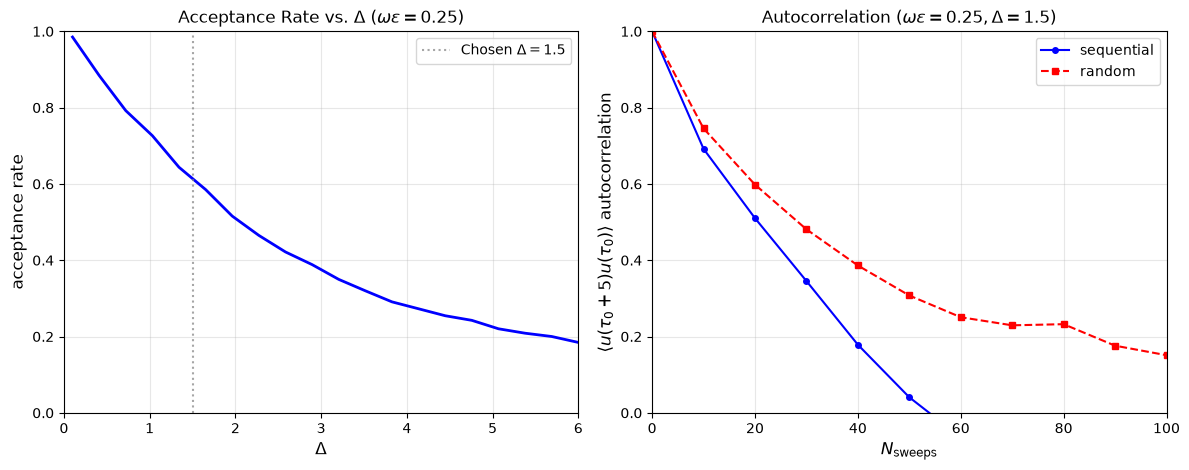

In [4]:
# Autocorrelation and acceptance rate analysis for the SHO lattice example from the article

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)

# =====================================================================
# 1. SHO Lattice Parameters (Article Section 4)
# =====================================================================
omega_eps = 0.25
kappa = 0.25 * (omega_eps ** 2)
g = (1.0 - kappa) / (1.0 + kappa)
Nt = 1000  # Path has slices j = 0, 1, ..., Nt with u_0 = u_Nt = 0

# =====================================================================
# 2. Sequential and Random Sweep Functions
# =====================================================================
def sweep_sequential(u, g, Delta, rng):
    """Updates interior slices j = 1, ..., Nt-1 in sequential order."""
    Nt = len(u) - 1
    deltas = rng.uniform(-Delta, Delta, size=Nt) # an array of random deltas for each slice
    rands = rng.uniform(0.0, 1.0, size=Nt) # an array of random numbers for acceptance check
    accepted = 0 # Count of accepted updates
    
    for j in range(1, Nt): # skip the boundary slices j=0 and j=Nt
        d = deltas[j]
        # Local action change: dS/hbar = d * (d + 2*u_j - g*(u_{j-1} + u_{j+1}))
        dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1]))
        if dS <= 0.0 or rands[j] < np.exp(-dS): # Accept with probability min(1, exp(-dS))
            u[j] += d
            accepted += 1
            
    return accepted / (Nt - 1)

def sweep_random(u, g, Delta, rng):
    """Updates Nt randomly chosen interior slices j in {1, ..., Nt-1}."""
    Nt = len(u) - 1
    j_indices = rng.integers(1, Nt, size=Nt) # an array of randomly chosen indices
    deltas = rng.uniform(-Delta, Delta, size=Nt) # an array of random deltas for each slice
    rands = rng.uniform(0.0, 1.0, size=Nt) # an array of random numbers for acceptance check
    accepted = 0 # Count of accepted updates
    
    for k in range(Nt):
        j = j_indices[k]
        d = deltas[k]
        dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1]))
        if dS <= 0.0 or rands[k] < np.exp(-dS): # Accept with probability min(1, exp(-dS))
            u[j] += d
            accepted += 1
            
    return accepted / Nt

def measure_correlator_lag(u, lag=5, i_start=200, i_end=800): # i_start and i_end define the middle region of the path to avoid boundary effects
    """Measures <u(tau0 + lag) u(tau0)> averaged over the middle region."""
    return np.mean(u[i_start : i_end] * u[i_start + lag : i_end + lag])

def compute_autocorr(series, max_lag=100):
    """Computes normalized autocorrelation rho(tau) for lags 0..max_lag."""
    fluct = series - np.mean(series)
    R0 = np.mean(fluct**2)
    N = len(series)
    rho = np.ones(max_lag + 1)
    for h in range(1, max_lag + 1):
        rho[h] = np.sum(fluct[:-h] * fluct[h:]) / ((N - h) * R0)
    return rho

# =====================================================================
# 3. Left Plot of Fig. 8: Acceptance Rate vs. Delta
# =====================================================================
delta_grid = np.linspace(0.1, 6.0, 20)
acc_rates = []

for d_val in delta_grid:
    u_temp = np.zeros(Nt + 1)
    # Quick thermalization + measurement of acceptance rate
    for _ in range(30):
        sweep_sequential(u_temp, g, d_val, rng)
    acc = np.mean([sweep_sequential(u_temp, g, d_val, rng) for _ in range(20)])
    acc_rates.append(acc)

# =====================================================================
# 4. Right Plot of Fig. 8: Autocorrelation (Sequential vs. Random)
# =====================================================================
Delta = 1.5
n_therm = 300
n_track = 3000  # Consecutive sweeps to measure autocorrelation up to lag 100

# A) Sequential sweeps
u_seq = np.zeros(Nt + 1)
for _ in range(n_therm):
    sweep_sequential(u_seq, g, Delta, rng) # thermalization sweeps
obs_seq = np.array([
    (sweep_sequential(u_seq, g, Delta, rng), measure_correlator_lag(u_seq, lag=5))[1]
    for _ in range(n_track)
])

# B) Random sweeps
u_rand = np.zeros(Nt + 1)
for _ in range(n_therm):
    sweep_random(u_rand, g, Delta, rng) # thermalization sweeps
obs_rand = np.array([
    (sweep_random(u_rand, g, Delta, rng), measure_correlator_lag(u_rand, lag=5))[1]
    for _ in range(n_track)
])

lags = np.arange(0, 101, 10)
rho_seq = compute_autocorr(obs_seq, max_lag=100)[lags] # lags = 0, 10, 20, ..., 100
rho_rand = compute_autocorr(obs_rand, max_lag=100)[lags]

# =====================================================================
# 5. Plot Reproduction of Fig. 8
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: Acceptance Rate vs Delta
ax1.plot(delta_grid, acc_rates, 'b-', lw=2)
ax1.axvline(1.5, color='gray', ls=':', alpha=0.7, label=r'Chosen $\Delta = 1.5$')
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 1.0)
ax1.set_xlabel(r'$\Delta$', fontsize=12)
ax1.set_ylabel('acceptance rate', fontsize=12)
ax1.set_title(r'Acceptance Rate vs. $\Delta$ ($\omega\varepsilon = 0.25$)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right Panel: Autocorrelation vs N_sweeps
ax2.plot(lags, rho_seq, 'b-o', markersize=4, label='sequential')
ax2.plot(lags, rho_rand, 'r--s', markersize=4, label='random')
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 1.0)
ax2.set_xlabel(r'$N_{\mathrm{sweeps}}$', fontsize=12)
ax2.set_ylabel(r'$\langle u(\tau_0+5)u(\tau_0)\rangle$ autocorrelation', fontsize=12)
ax2.set_title(r'Autocorrelation ($\omega\varepsilon = 0.25, \Delta = 1.5$)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

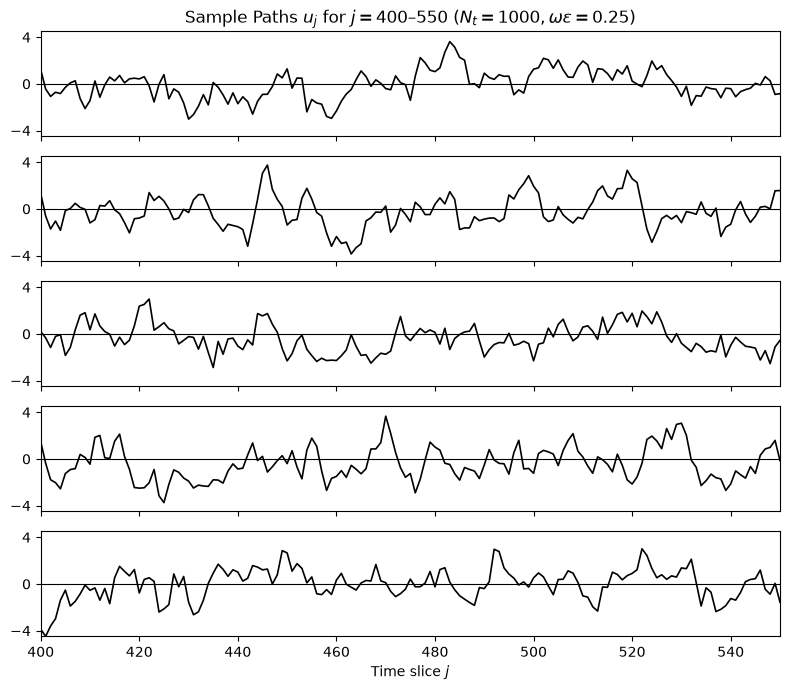

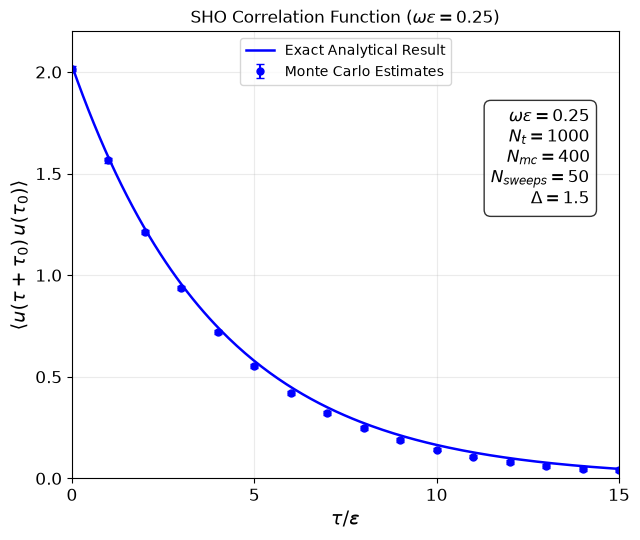

In [5]:
# =====================================================================
# Reproducing Fig. 9 (Sample Paths) and Fig. 10 (Correlation Function)
# =====================================================================
Delta = 1.5
N_therm = 500
N_sweeps = 50    # Sweeps skipped between saved measurements
N_mc = 400       # Number of decorrelated path measurements
max_tau = 15     # Evaluate <u(tau0 + tau) u(tau0)> for tau/eps = 0..15

u = np.zeros(Nt + 1)  # Cold start: u_j = 0 for all j

# 1. Thermalization Phase
for _ in range(N_therm):
    sweep_sequential(u, g, Delta, rng)

# 2. Measurement Phase
saved_paths = []
corr_samples = np.zeros((N_mc, max_tau + 1)) # Store <u(tau0 + tau) u(tau0)> for each decorrelated path. max_tau + 1 because we include tau=0.
i_start, i_end = 200, 800  # Bulk interior region away from ends u_0 = u_Nt = 0

for m in range(N_mc):
    # Skip N_sweeps between measurements to decorrelate paths
    for _ in range(N_sweeps):
        sweep_sequential(u, g, Delta, rng)
        
    # Save first 5 decorrelated paths for Fig. 9 (slices j = 400..550)
    if m < 5:
        saved_paths.append(u[400:551].copy())
        
    # Measure <u(tau0 + tau) u(tau0)> averaged over interior tau0 slices
    u_base = u[i_start:i_end]
    for tau in range(max_tau + 1):
        corr_samples[m, tau] = np.mean(u_base * u[i_start + tau : i_end + tau])

# Compute Monte Carlo mean and standard error for each tau
mc_corr_mean = np.mean(corr_samples, axis=0) # axis 0 means operating over rows, which gives result for each column (tau)
mc_corr_err = np.std(corr_samples, axis=0, ddof=1) / np.sqrt(N_mc) # ddof=1 gives unbiased sample standard deviation

# Exact analytical lattice propagator
tau_vals = np.arange(0, max_tau + 1)
tau_fine = np.linspace(0, max_tau, 200)
sqrt_k = 0.5 * omega_eps
exact_curve = ((1.0 + kappa) / (4.0 * sqrt_k)) * ((1.0 - sqrt_k) / (1.0 + sqrt_k)) ** tau_fine

# =====================================================================
# Plot Fig. 9: 5 Sample Quantum Paths for j = 400 - 550
# =====================================================================
fig, axes = plt.subplots(5, 1, figsize=(8, 7), sharex=True)
j_slice = np.arange(400, 551)

for idx, ax in enumerate(axes): # enumerate gives both the index and the element from saved_paths
    ax.plot(j_slice, saved_paths[idx], 'k-', lw=1.2)
    ax.axhline(0.0, color='black', lw=0.8)
    ax.set_ylim(-4.5, 4.5)
    ax.set_yticks([-4, 0, 4])
    ax.set_xlim(400, 550)

axes[0].set_title(r'Sample Paths $u_j$ for $j = 400\text{–}550$ ($N_t = 1000, \omega\varepsilon = 0.25$)')
axes[-1].set_xlabel('Time slice $j$')
plt.tight_layout()
plt.show()

# =====================================================================
# Plot Fig. 10: Two-Point Correlation Function <u(tau0 + tau) u(tau0)>
# =====================================================================
plt.figure(figsize=(6.5, 5.5))
plt.plot(tau_fine, exact_curve, 'b-', lw=1.8, label='Exact Analytical Result')
plt.errorbar(tau_vals, mc_corr_mean, yerr=mc_corr_err, fmt='bo', markersize=5,
             capsize=3, label='Monte Carlo Estimates')

plt.xlim(0, 15)
plt.ylim(0, 2.2)
plt.xticks([0, 5, 10, 15], fontsize=12)
plt.yticks([0, 0.5, 1, 1.5, 2], fontsize=12)
plt.xlabel(r'$\tau / \varepsilon$', fontsize=14)
plt.ylabel(r'$\langle u(\tau + \tau_0)\, u(\tau_0) \rangle$', fontsize=14)
plt.title(r'SHO Correlation Function ($\omega\varepsilon = 0.25$)')

# Add parameter text box matching Fig. 10
info_text = (
    rf"$\omega\varepsilon = {omega_eps}$" + "\n" +
    rf"$N_t = {Nt}$" + "\n" +
    rf"$N_{{mc}} = {N_mc}$" + "\n" +
    rf"$N_{{sweeps}} = {N_sweeps}$" + "\n" +
    rf"$\Delta = {Delta}$"
)
plt.text(14.2, 1.35, info_text, fontsize=12, horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8))

plt.legend(loc='upper center', fontsize=10)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

question 1 : The autocorrelation changing with seed value ?
question 2 : The amplitude looks bounded between 4 and -4 ?
question 3 : N_sweeps decorrelate ? That's why error is simple sigma ?